**Upload**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

os.listdir("/content/drive/MyDrive")

folder_path = "/content/drive/MyDrive/Walmart Recruiting Sales Data"

In [ ]:
import pandas as pd
import os

# Diagnostic: check if the path exists and list its parent directory contents to verify the folder name
mydrive_path = "/content/drive/MyDrive"
if os.path.exists(mydrive_path):
    print("Contents of MyDrive:", os.listdir(mydrive_path))
else:
    print("Google Drive is not mounted or path does not exist.")

train = pd.read_csv(folder_path + "/train.csv")
features = pd.read_csv(folder_path + "/features.csv")
stores = pd.read_csv(folder_path + "/stores.csv")

print(train.shape)
print(features.shape)
print(stores.shape)


Contents of MyDrive: ['AirQuality.csv', 'Copy of MKTG 455 theme and topic selection.gform', 'USG short prez.gslides', 'MACY 7Cs framework.gslides', 'Resolution 2022-F6-1003.pdf', 'Copy of Emotional Intelligence and Anger Management Meeting Business by Slidesgo.gslides', 'Netflix PPT.pptx', 'FREE VER- Netflix Inspired PPT Template by Gemo Edits - Copy.pptx', 'NETFLIX.gslides', '919 S Aberdeen St - QuynhNhuDinh-102-1-7-23 renew Unsigned.pdf', '919 S Aberdeen St - QuynhNhuDinh-102-1-7-23 renew Unsigned.gdoc', 'Untitled document (95).gdoc', '2nd: .gdoc', 'Untitled document (94).gdoc', 'MKTG 452 Retail Career Assignment instructions .pdf', 'sailing80.mp3', 'To him:.gdoc', 'Untitled document (93).gdoc', 'Quynh Nhu Dinh - 662499552.gdoc', 'Untitled document (92).gdoc', '2nd and 3rd show: TET.gdoc', 'Cost Concepts Solutions - Spring 2023.pdf', 'usgcls.gdoc', 'IMG_0387.JPG', 'Assignment 2.gdoc', 'S3 Packet.pdf', 'DonationGuidelines_11x17 (5) (1).pdf', '3-Tri-Fold Brochure_5x7 (4).pdf', "Movie's

**Merging**

In [ ]:
train["Date"] = pd.to_datetime(train["Date"])
features["Date"] = pd.to_datetime(features["Date"])

df = train.merge(
    features,
    on=["Store", "Date", "IsHoliday"],
    how="left"
)

df = df.merge(
    stores,
    on="Store",
    how="left"
)

print("Final shape:", df.shape)
display(df.head())

Final shape: (421570, 16)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,A,151315


**EDA**

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
# 1. Basic structure
print(df.shape)
print(df.columns.tolist())

df.info()

(421570, 16)
['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'Type', 'Size']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         421570 non-null  int64         
 1   Dept          421570 non-null  int64         
 2   Date          421570 non-null  datetime64[ns]
 3   Weekly_Sales  421570 non-null  float64       
 4   IsHoliday     421570 non-null  bool          
 5   Temperature   421570 non-null  float64       
 6   Fuel_Price    421570 non-null  float64       
 7   MarkDown1     150681 non-null  float64       
 8   MarkDown2     111248 non-null  float64       
 9   MarkDown3     137091 non-null  float64       
 10  MarkDown4     134967 non-null  float64       
 11  MarkDown5     151432

In [ ]:
# 2. Missing values
missing = df.isnull().sum().sort_values(ascending=False)

missing_percent = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

missing_summary = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percent": missing_percent
})

display(missing_summary)

,Missing_Count,Missing_Percent
MarkDown2,310322,73.611025
MarkDown4,286603,67.984676
MarkDown3,284479,67.480845
MarkDown1,270889,64.257181
MarkDown5,270138,64.079038
Store,0,0.000000
Date,0,0.000000
Dept,0,0.000000
Fuel_Price,0,0.000000
Temperature,0,0.000000


In [ ]:
# 3. Descriptive statistics
display(df.describe())

,Store,Dept,Date,Weekly_Sales,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Size
count,421570.000000,421570.000000,421570,421570.000000,421570.000000,421570.000000,150681.000000,111248.000000,137091.000000,134967.000000,151432.000000,421570.000000,421570.000000,421570.000000
mean,22.200546,44.260317,2011-06-18 08:30:31.963375104,15981.258123,60.090059,3.361027,7246.420196,3334.628621,1439.421384,3383.168256,4628.975079,171.201947,7.960289,136727.915739
min,1.000000,1.000000,2010-02-05 00:00:00,-4988.940000,-2.060000,2.472000,0.270000,-265.760000,-29.100000,0.220000,135.160000,126.064000,3.879000,34875.000000
25%,11.000000,18.000000,2010-10-08 00:00:00,2079.650000,46.680000,2.933000,2240.270000,41.600000,5.080000,504.220000,1878.440000,132.022667,6.891000,93638.000000
50%,22.000000,37.000000,2011-06-17 00:00:00,7612.030000,62.090000,3.452000,5347.450000,192.000000,24.600000,1481.310000,3359.450000,182.318780,7.866000,140167.000000
75%,33.000000,74.000000,2012-02-24 00:00:00,20205.852500,74.280000,3.738000,9210.900000,1926.940000,103.990000,3595.040000,5563.800000,212.416993,8.572000,202505.000000
max,45.000000,99.000000,2012-10-26 00:00:00,693099.360000,100.140000,4.468000,88646.760000,104519.540000,141630.610000,67474.850000,108519.280000,227.232807,14.313000,219622.000000
std,12.785297,30.492054,NaN,22711.183519,18.447931,0.458515,8291.221345,9475.357325,9623.078290,6292.384031,5962.887455,39.159276,1.863296,60980.583328


In [ ]:
# 4. Date range
print("Start date:", df["Date"].min())
print("End date:", df["Date"].max())
print("Number of weeks:", df["Date"].nunique())

Start date: 2010-02-05 00:00:00
End date: 2012-10-26 00:00:00
Number of weeks: 143


In [ ]:
# 5. Coverage
print("Number of stores:", df["Store"].nunique())
print("Number of departments:", df["Dept"].nunique())

print("\nStore types:")
print(df["Type"].value_counts())
stores["Type"].value_counts()

Number of stores: 45
Number of departments: 81

Store types:
Type
A    215478
B    163495
C     42597
Name: count, dtype: int64


,count
Type,
A,22
B,17
C,6


**Markdown EDA**

In [ ]:
markdown_cols = [
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5"
]

df["Has_Markdown"] = df[markdown_cols].notna().any(axis=1)

markdown_summary = pd.DataFrame({
    "Count": df["Has_Markdown"].value_counts(),
    "Percent": df["Has_Markdown"].value_counts(normalize=True) * 100
})

markdown_summary

,Count,Percent
Has_Markdown,,
False,270138,64.079038
True,151432,35.920962


Approximately 35.9% of observations contain at least one recorded markdown value, while 64.1% contain no recorded markdown information. This shows that markdown information is available for 1/3 of the dataset.

In [ ]:
markdown_missing = df[markdown_cols].isnull().mean() * 100

markdown_missing

,0
MarkDown1,64.257181
MarkDown2,73.611025
MarkDown3,67.480845
MarkDown4,67.984676
MarkDown5,64.079038


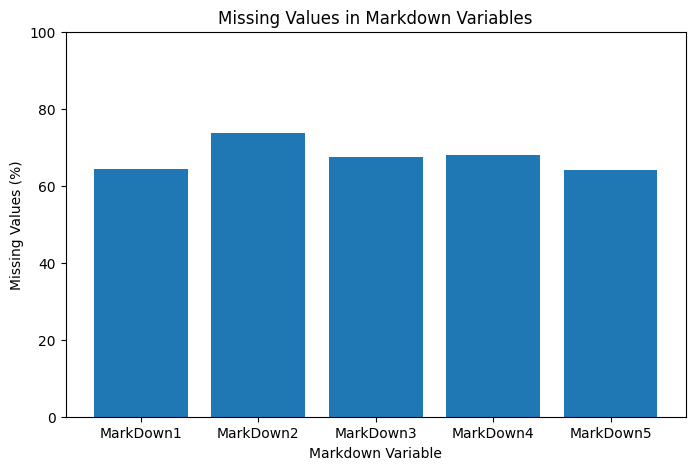

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(markdown_missing.index, markdown_missing.values)

plt.title("Missing Values in Markdown Variables")
plt.xlabel("Markdown Variable")
plt.ylabel("Missing Values (%)")
plt.ylim(0, 100)

plt.show()

MarkDown2 has the highest level of missingness. These missing values should be handled carefully because they may represent either no markdown or discount activity or unavailable markdown information.

In [ ]:
df[markdown_cols].describe().round(2)

,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5
count,150681.00,111248.00,137091.00,134967.00,151432.00
mean,7246.42,3334.63,1439.42,3383.17,4628.98
std,8291.22,9475.36,9623.08,6292.38,5962.89
min,0.27,-265.76,-29.10,0.22,135.16
25%,2240.27,41.60,5.08,504.22,1878.44
50%,5347.45,192.00,24.60,1481.31,3359.45
75%,9210.90,1926.94,103.99,3595.04,5563.80
max,88646.76,104519.54,141630.61,67474.85,108519.28


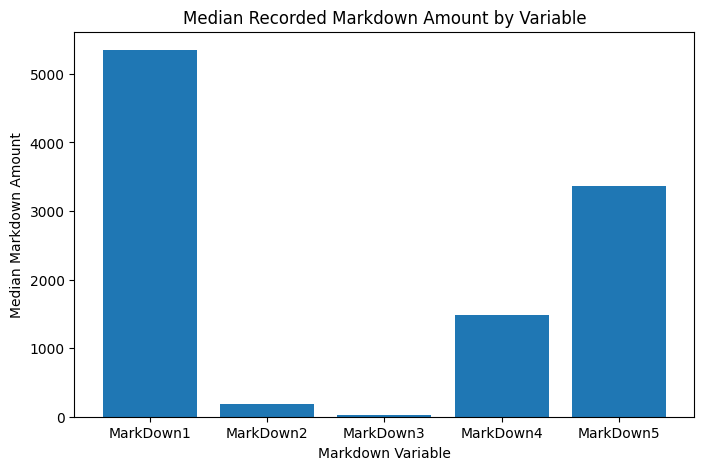

In [ ]:
markdown_medians = df[markdown_cols].median()

plt.figure(figsize=(8,5))

plt.bar(markdown_medians.index, markdown_medians.values)

plt.title("Median Recorded Markdown Amount by Variable")
plt.xlabel("Markdown Variable")
plt.ylabel("Median Markdown Amount")

plt.show()

Markdown amounts differ substantially across the five variables. MarkDown1 has the largest typical recorded amount, while MarkDown2 and MarkDown3 have much smaller medians. Large differences between the median, mean, and maximum values also suggest that the markdown variables contain highly skewed distributions and some unusually large values.

In [ ]:
markdown_sales_summary = df.groupby("Has_Markdown")["Weekly_Sales"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std"
).round(2)

markdown_sales_summary

,count,mean,median,std
Has_Markdown,,,,
False,270138,15871.52,7654.84,22411.83
True,151432,16177.02,7537.87,23234.41


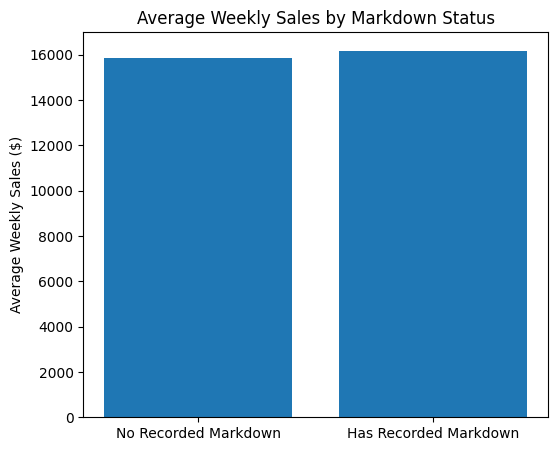

In [ ]:
markdown_avg_sales = df.groupby("Has_Markdown")["Weekly_Sales"].mean()

plt.figure(figsize=(6,5))

plt.bar(
    ["No Recorded Markdown", "Has Recorded Markdown"],
    [
        markdown_avg_sales.get(False, 0),
        markdown_avg_sales.get(True, 0)
    ]
)

plt.title("Average Weekly Sales by Markdown Status")
plt.ylabel("Average Weekly Sales ($)")

plt.show()

Average weekly sales are slightly higher for observations with recorded markdown activity. However, median sales are very similar and are slightly lower for observations with markdowns. Therefore, the simple comparison does not show a strong or consistent relationship between markdown activity and sales.
This comparison is descriptive and does not show that markdowns caused the difference in sales. Holiday timing, department, store characteristics, seasonality, and other factors may also influence weekly sales.

Holidays EDA

In [ ]:
df.groupby("IsHoliday")["Weekly_Sales"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
IsHoliday,,,,
False,391909,15901.445069,7589.95,22330.747450
True,29661,17035.823187,7947.74,27222.000409


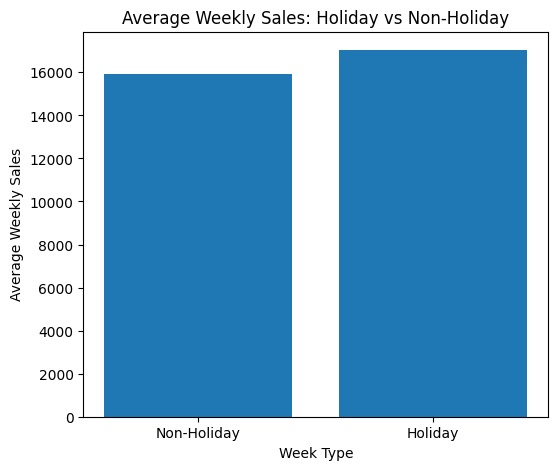

In [ ]:
holiday_sales = df.groupby("IsHoliday")["Weekly_Sales"].mean()

plt.figure(figsize=(6,5))
plt.bar(["Non-Holiday", "Holiday"], holiday_sales.values)
plt.title("Average Weekly Sales: Holiday vs Non-Holiday")
plt.xlabel("Week Type")
plt.ylabel("Average Weekly Sales")
plt.show()

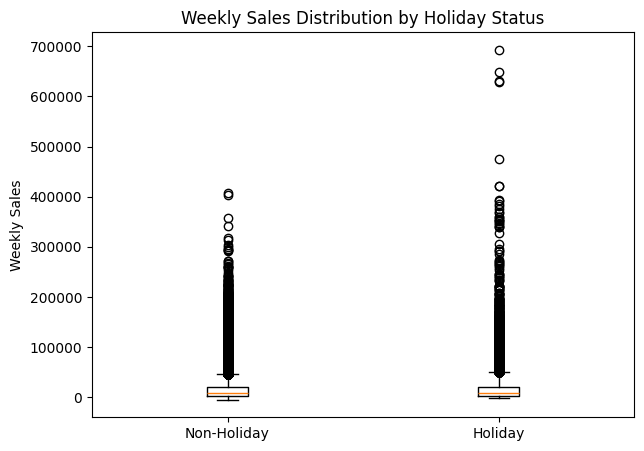

In [ ]:
holiday_false = df[df["IsHoliday"] == False]["Weekly_Sales"]
holiday_true = df[df["IsHoliday"] == True]["Weekly_Sales"]

plt.figure(figsize=(7,5))
plt.boxplot([holiday_false, holiday_true], tick_labels=["Non-Holiday", "Holiday"])
plt.title("Weekly Sales Distribution by Holiday Status")
plt.ylabel("Weekly Sales")
plt.show()

Holiday weeks show higher average and median weekly sales than non-holiday weeks, with greater variability. Holiday timing should therefore be considered when evaluating markdown performance, because sales differences may reflect seasonal demand rather than markdown effects alone.

**1. Weekly Sales Over Time**

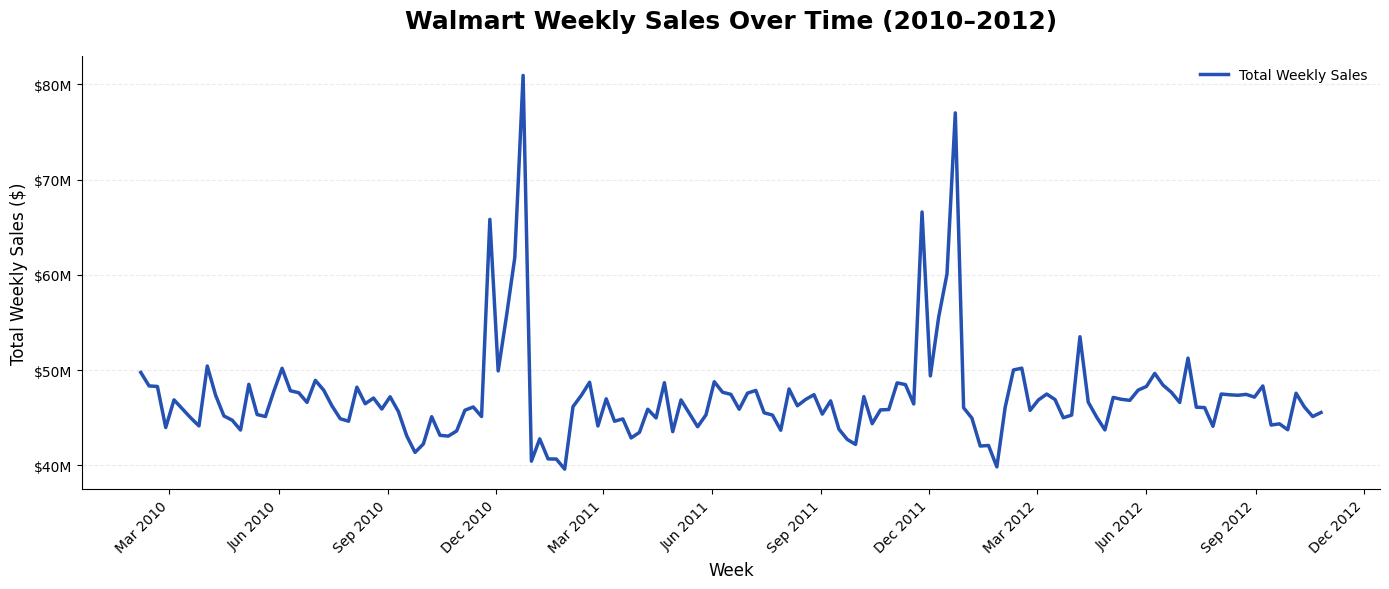

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# 1. Prepare data
data = df.copy()
data["Date"] = pd.to_datetime(data["Date"])

# Total weekly sales across all stores and departments
weekly_sales = (
    data.groupby("Date", as_index=False)["Weekly_Sales"]
    .sum()
    .sort_values("Date")
)

# 2. Create chart
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    weekly_sales["Date"],
    weekly_sales["Weekly_Sales"],
    color="#2451B2",
    linewidth=2.5,
    label="Total Weekly Sales"
)

# 3. Format chart
ax.set_title(
    "Walmart Weekly Sales Over Time (2010–2012)",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Week", fontsize=12)
ax.set_ylabel("Total Weekly Sales ($)", fontsize=12)

# Format sales in millions
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x/1e6:.0f}M")
)

# Format dates
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.xticks(rotation=45, ha="right")

# Clean styling
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(loc="upper right", frameon=False)

plt.tight_layout()
plt.show()


Average weekly sales remain relatively stable throughout most of the period, but large spikes occur near the end of each year. These peaks suggest strong seasonal and holiday effects on sales. Because sales naturally increase during certain periods, time and seasonality should be considered when evaluating whether a markdown is underperforming.

**2. Department-Level Sales Distribution**

In [ ]:
# Total unique department IDs
print("Unique departments:", df["Dept"].nunique())

# Unique departments within each store
dept_per_store = df.groupby("Store")["Dept"].nunique()

print("Minimum departments per store:", dept_per_store.min())
print("Maximum departments per store:", dept_per_store.max())

# Actual number of store-department combinations
print(
    "Total store-department combinations:",
    df[["Store", "Dept"]].drop_duplicates().shape[0]
)

Unique departments: 81
Minimum departments per store: 61
Maximum departments per store: 79
Total store-department combinations: 3331


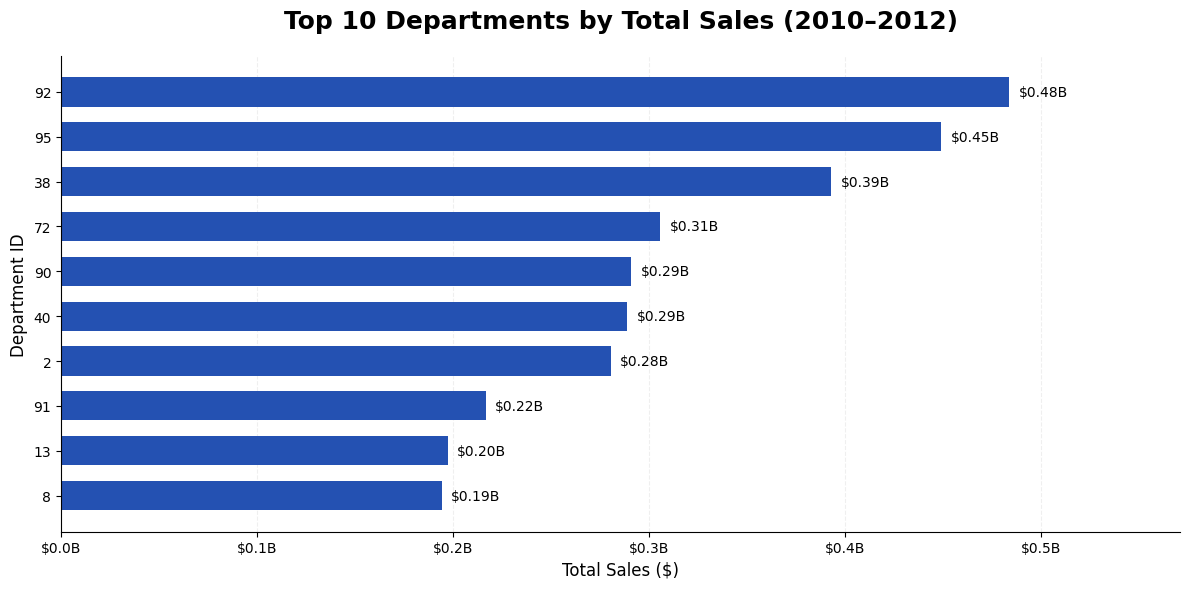

,Dept,Weekly_Sales
73,92,4.839433e+08
76,95,4.493202e+08
36,38,3.931181e+08
60,72,3.057252e+08
71,90,2.910685e+08
38,40,2.889360e+08
1,2,2.806112e+08
72,91,2.167817e+08
12,13,1.973216e+08
7,8,1.942808e+08


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# --------------------------------------------------
# 1. Prepare data
# --------------------------------------------------

data = df.copy()
data["Date"] = pd.to_datetime(data["Date"])

# Avoid duplicated store-department-week records
data = data.drop_duplicates(
    subset=["Store", "Dept", "Date"]
)

# --------------------------------------------------
# 2. Calculate total sales by department
# --------------------------------------------------

dept_sales = (
    data.groupby("Dept", as_index=False)["Weekly_Sales"]
    .sum()
    .sort_values("Weekly_Sales", ascending=False)
)

top10_depts = dept_sales.head(10).copy()

# Sort for horizontal chart
top10_depts = top10_depts.sort_values("Weekly_Sales")

# --------------------------------------------------
# 3. Create professional bar chart
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    top10_depts["Dept"].astype(str),
    top10_depts["Weekly_Sales"],
    color="#2451B2",
    height=0.65
)

# Display sales values at end of each bar
for bar in bars:
    value = bar.get_width()
    ax.text(
        value + dept_sales["Weekly_Sales"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"${value/1e9:.2f}B",
        va="center",
        fontsize=10
    )

# --------------------------------------------------
# 4. Formatting
# --------------------------------------------------

ax.set_title(
    "Top 10 Departments by Total Sales (2010–2012)",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Total Sales ($)", fontsize=12)
ax.set_ylabel("Department ID", fontsize=12)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x/1e9:.1f}B")
)

ax.set_xlim(
    0,
    top10_depts["Weekly_Sales"].max() * 1.18
)

ax.grid(axis="x", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 5. Display top 10 department values
# --------------------------------------------------

display(
    dept_sales.head(10).round(2)
)


**3. Markdown Data Availability & Missingness**

In [ ]:

# Markdown Data Availability Check

import pandas as pd

markdown_cols = [
    "MarkDown1", "MarkDown2", "MarkDown3",
    "MarkDown4", "MarkDown5"
]

# Create store-week markdown data from existing merged df
markdown_data = (
    df.groupby(["Store", "Date"], as_index=False)[markdown_cols]
    .first()
)

# Identify weeks with at least one recorded markdown
has_markdown_data = (
    markdown_data[markdown_cols].notna().any(axis=1)
)

print(
    "Store-weeks with at least one recorded markdown:",
    has_markdown_data.sum()
)

print(
    "Percentage with at least one recorded markdown:",
    f"{has_markdown_data.mean() * 100:.1f}%"
)


Store-weeks with at least one recorded markdown: 2295
Percentage with at least one recorded markdown: 35.7%


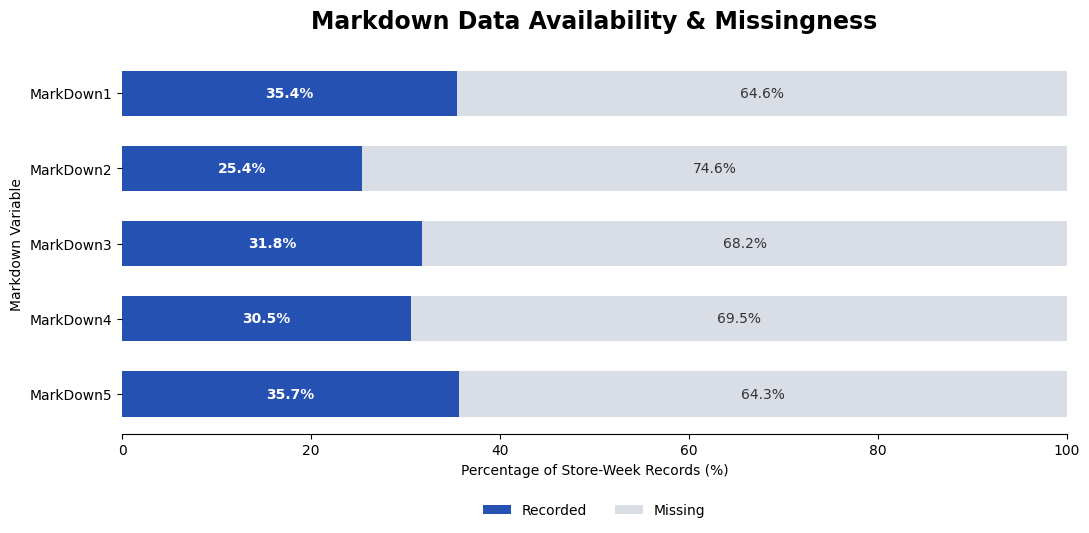

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------
# 1. Prepare data
# -------------------------------------------

data = df.copy()
data["Date"] = pd.to_datetime(data["Date"])

markdown_cols = [
    "MarkDown1", "MarkDown2", "MarkDown3",
    "MarkDown4", "MarkDown5"
]

# Keep one record per store-week
# Markdown fields are recorded at store-week level
markdown_data = (
    data.sort_values(["Store", "Date"])
    .groupby(["Store", "Date"], as_index=False)[markdown_cols]
    .first()
)

# -------------------------------------------
# 2. Calculate availability percentages
# -------------------------------------------

recorded_pct = (
    markdown_data[markdown_cols].notna().mean() * 100
)

missing_pct = 100 - recorded_pct

# -------------------------------------------
# 3. Create chart
# -------------------------------------------

fig, ax = plt.subplots(figsize=(11, 5.5))

y = np.arange(len(markdown_cols))

ax.barh(
    y, recorded_pct.values,
    color="#2451B2",
    label="Recorded",
    height=0.6
)

ax.barh(
    y, missing_pct.values,
    left=recorded_pct.values,
    color="#D9DDE5",
    label="Missing",
    height=0.6
)

# Percentage labels
for i, (rec, miss) in enumerate(
    zip(recorded_pct, missing_pct)
):
    if rec > 8:
        ax.text(
            rec / 2, i, f"{rec:.1f}%",
            ha="center", va="center",
            color="white", fontweight="bold"
        )

    if miss > 8:
        ax.text(
            rec + miss / 2, i, f"{miss:.1f}%",
            ha="center", va="center",
            color="#333333"
        )

# -------------------------------------------
# 4. Formatting
# -------------------------------------------

ax.set_yticks(y)
ax.set_yticklabels(markdown_cols)
ax.invert_yaxis()

ax.set_xlim(0, 100)

ax.set_title(
    "Markdown Data Availability & Missingness",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Percentage of Store-Week Records (%)")
ax.set_ylabel("Markdown Variable")

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=2,
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.show()


**4. Department-Level Sales Volatility**

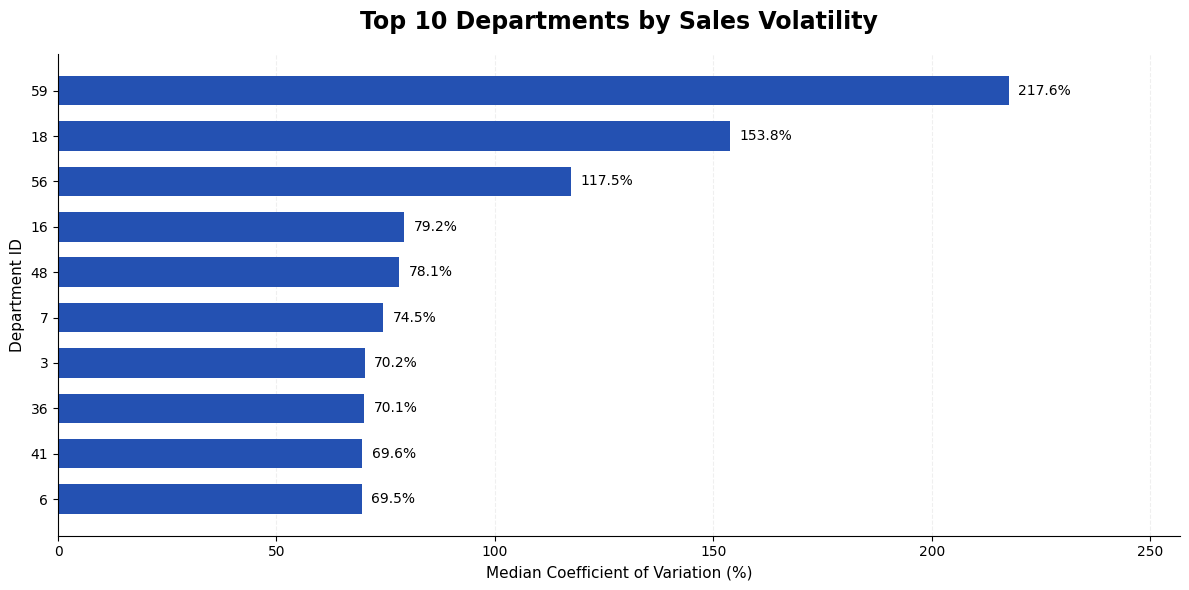

,Dept,Median_CV,Stores
49,59,217.61,11
16,18,153.84,37
47,56,117.48,35
14,16,79.25,41
42,48,78.06,10
6,7,74.49,37
2,3,70.22,38
34,36,70.12,31
38,41,69.64,28
5,6,69.55,37


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------
# 1. Prepare data
# -------------------------------------------

data = df.copy()
data["Date"] = pd.to_datetime(data["Date"])

# Use one row per Store-Department-Week
# Check uniqueness before aggregating
keys = ["Store", "Dept", "Date"]

if data.duplicated(keys).any():
    raise ValueError(
        "Duplicate Store-Dept-Date records found. "
        "Please verify the merge before calculating volatility."
    )

# -------------------------------------------
# 2. Calculate volatility within each
#    Store-Department combination
# -------------------------------------------

dept_volatility = (
    data.groupby(["Store", "Dept"])
    .agg(
        Mean_Sales=("Weekly_Sales", "mean"),
        Std_Sales=("Weekly_Sales", "std"),
        Weeks=("Weekly_Sales", "count")
    )
    .reset_index()
)

# Require enough observations for comparison
dept_volatility = dept_volatility[
    (dept_volatility["Weeks"] >= 52) &
    (dept_volatility["Mean_Sales"] >= 1000)
].copy()

# Coefficient of variation
dept_volatility["CV"] = (
    dept_volatility["Std_Sales"]
    / dept_volatility["Mean_Sales"]
) * 100

# -------------------------------------------
# 3. Summarize by department
# -------------------------------------------

dept_summary = (
    dept_volatility.groupby("Dept")
    .agg(
        Median_CV=("CV", "median"),
        Stores=("Store", "nunique")
    )
    .reset_index()
)

# Require at least 10 stores for comparison
dept_summary = dept_summary[
    dept_summary["Stores"] >= 10
]

top10_volatile = (
    dept_summary
    .nlargest(10, "Median_CV")
    .sort_values("Median_CV")
)

# -------------------------------------------
# 4. Create chart
# -------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    top10_volatile["Dept"].astype(str),
    top10_volatile["Median_CV"],
    color="#2451B2",
    height=0.65
)

# Add labels
for bar in bars:
    value = bar.get_width()

    ax.text(
        value + top10_volatile["Median_CV"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=10
    )

# -------------------------------------------
# 5. Formatting
# -------------------------------------------

ax.set_title(
    "Top 10 Departments by Sales Volatility",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Median Coefficient of Variation (%)",
    fontsize=11
)

ax.set_ylabel("Department ID", fontsize=11)

ax.set_xlim(
    0,
    top10_volatile["Median_CV"].max() * 1.18
)

ax.grid(axis="x", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# Display numerical results
display(
    top10_volatile.sort_values(
        "Median_CV", ascending=False
    ).round(2)
)


In [ ]:
print(df.columns.tolist())

['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'Type', 'Size', 'Has_Markdown']


**MODEL COMPARISON**

In [29]:

# ============================================================
# WALMART FORECASTING MODEL COMPARISON
# 6 models | 3 chronological validations | Final holdout test
# ============================================================

!pip -q install xgboost lightgbm

import os
import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# ------------------------------------------------------------
# 1. READ ORIGINAL DATASETS FROM GOOGLE DRIVE
# ------------------------------------------------------------

# Your existing notebook already defines folder_path.
# For example:
# folder_path = "/content/drive/MyDrive/Walmart Recruiting Sales Data"

if "folder_path" not in globals():
    folder_path = "/content/drive/MyDrive/Walmart Recruiting Sales Data"

sales = pd.read_csv(
    os.path.join(folder_path, "train.csv"),
    parse_dates=["Date"]
)

features_data = pd.read_csv(
    os.path.join(folder_path, "features.csv"),
    parse_dates=["Date"]
)

stores_data = pd.read_csv(
    os.path.join(folder_path, "stores.csv")
)

# Merge only the ORIGINAL files
model_df = sales.merge(
    features_data,
    on=["Store", "Date", "IsHoliday"],
    how="left",
    validate="many_to_one"
)

model_df = model_df.merge(
    stores_data,
    on="Store",
    how="left",
    validate="many_to_one"
)

model_df = model_df.sort_values(
    ["Store", "Dept", "Date"]
).reset_index(drop=True)

assert "Type" in model_df.columns
assert "Size" in model_df.columns
assert not any(
    c.endswith(("_x", "_y"))
    for c in model_df.columns
)

print("Original observations:", len(model_df))
print("Stores:", model_df["Store"].nunique())
print("Departments:", model_df["Dept"].nunique())
print("Dates:", model_df["Date"].min(), "to", model_df["Date"].max())

# ------------------------------------------------------------
# 2. FEATURE ENGINEERING
# ------------------------------------------------------------

model_df["Year"] = model_df["Date"].dt.year
model_df["Month"] = model_df["Date"].dt.month
model_df["Week"] = (
    model_df["Date"].dt.isocalendar().week.astype(int)
)

model_df["Week_Sin"] = np.sin(
    2 * np.pi * model_df["Week"] / 52
)
model_df["Week_Cos"] = np.cos(
    2 * np.pi * model_df["Week"] / 52
)

model_df["IsHoliday"] = model_df["IsHoliday"].astype(int)

for t in ["A", "B", "C"]:
    model_df[f"Type_{t}"] = (
        model_df["Type"] == t
    ).astype(int)

# IMPORTANT:
# Reindex each Store-Dept series to weekly Friday dates.
# This makes Lag_1 mean the previous calendar week,
# instead of the previous available observation.

original_rows = model_df.copy()
original_rows["Observed_Row"] = True

weekly_parts = []

for (store, dept), group in original_rows.groupby(
    ["Store", "Dept"], sort=False
):
    weekly = (
        group.set_index("Date")
        .sort_index()
        .asfreq("W-FRI")
    )

    weekly["Store"] = store
    weekly["Dept"] = dept

    weekly["Weekly_Sales"] = pd.to_numeric(
        weekly["Weekly_Sales"], errors="coerce"
    )

    history = weekly["Weekly_Sales"]

    for lag in [1, 2, 4, 8]:
        weekly[f"Lag_{lag}"] = history.shift(lag)

    for window in [4, 8]:
        weekly[f"MA_{window}"] = (
            history.shift(1)
            .rolling(window, min_periods=window)
            .mean()
        )

    weekly_parts.append(weekly.reset_index())

model_df = pd.concat(
    weekly_parts, ignore_index=True
)

# Use only actual observed store-department-weeks
model_df = model_df[
    model_df["Observed_Row"].eq(True)
].copy()

# Require the same historical lag coverage for all models
required_lags = [
    "Lag_1", "Lag_2", "Lag_4", "Lag_8",
    "MA_4", "MA_8"
]

model_df = model_df.dropna(
    subset=required_lags
).copy()

model_df["Baseline_8Week"] = model_df["MA_8"]

feature_cols = [
    "Store", "Dept", "Size", "IsHoliday",
    "Year", "Month", "Week",
    "Week_Sin", "Week_Cos",
    "Type_A", "Type_B", "Type_C",
    "Temperature", "Fuel_Price",
    "CPI", "Unemployment",
    "MarkDown1", "MarkDown2", "MarkDown3",
    "MarkDown4", "MarkDown5",
    "Lag_1", "Lag_2", "Lag_4", "Lag_8",
    "MA_4", "MA_8"
]

print("\nEligible observations:", len(model_df))
print("Missing model columns:",
      sorted(set(feature_cols) - set(model_df.columns)))

# ------------------------------------------------------------
# 3. DEFINE MODELS
# ------------------------------------------------------------

def get_models():
    return {
        "XGBoost": make_pipeline(
            SimpleImputer(strategy="median"),
            XGBRegressor(
                n_estimators=250,
                max_depth=8,
                learning_rate=0.07,
                objective="reg:squarederror",
                tree_method="hist",
                n_jobs=-1,
                random_state=42
            )
        ),

        "Extra Trees": make_pipeline(
            SimpleImputer(strategy="median"),
            ExtraTreesRegressor(
                n_estimators=150,
                min_samples_leaf=2,
                n_jobs=-1,
                random_state=42
            )
        ),

        "LightGBM": make_pipeline(
            SimpleImputer(strategy="median"),
            LGBMRegressor(
                n_estimators=250,
                learning_rate=0.07,
                n_jobs=-1,
                random_state=42,
                verbosity=-1
            )
        ),

        "Random Forest": make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestRegressor(
                n_estimators=100,
                min_samples_leaf=2,
                n_jobs=-1,
                random_state=42
            )
        ),

        "Ridge Regression": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            Ridge(alpha=1000)
        )
    }

# ------------------------------------------------------------
# 4. EVALUATION METRICS
# ------------------------------------------------------------

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    absolute_errors = np.abs(actual - predicted)

    mae = absolute_errors.mean()

    denominator = np.abs(actual).sum()
    wape = (
        absolute_errors.sum() / denominator * 100
        if denominator > 0 else np.nan
    )

    return wape, mae

# ------------------------------------------------------------
# 5. THREE CHRONOLOGICAL VALIDATION PERIODS
# ------------------------------------------------------------

validation_periods = [
    ("Validation 1", "2011-12-02", "2012-02-10"),
    ("Validation 2", "2012-02-17", "2012-04-27"),
    ("Validation 3", "2012-05-04", "2012-07-13")
]

validation_records = []

for fold_name, start, end in validation_periods:

    start = pd.Timestamp(start)
    end = pd.Timestamp(end)

    train_fold = model_df[
        model_df["Date"] < start
    ].copy()

    valid_fold = model_df[
        model_df["Date"].between(start, end)
    ].copy()

    print(f"\n{'=' * 50}")
    print(f"{fold_name}: {start.date()} to {end.date()}")
    print("Training observations:", len(train_fold))
    print("Validation observations:", len(valid_fold))

    for model_name, model in get_models().items():

        model.fit(
            train_fold[feature_cols],
            train_fold["Weekly_Sales"]
        )

        preds = model.predict(
            valid_fold[feature_cols]
        )

        wape, mae = calculate_metrics(
            valid_fold["Weekly_Sales"],
            preds
        )

        validation_records.append({
            "Model": model_name,
            "Period": fold_name,
            "WAPE": wape,
            "MAE": mae,
            "N": len(valid_fold)
        })

        print(f"{model_name}: WAPE {wape:.2f}%")

    # Same observations as the supervised models
    ma_wape, ma_mae = calculate_metrics(
        valid_fold["Weekly_Sales"],
        valid_fold["Baseline_8Week"]
    )

    validation_records.append({
        "Model": "8-Week Moving Average",
        "Period": fold_name,
        "WAPE": ma_wape,
        "MAE": ma_mae,
        "N": len(valid_fold)
    })

    print(f"8-Week Moving Average: WAPE {ma_wape:.2f}%")

validation_results = pd.DataFrame(validation_records)

validation_table = validation_results.pivot(
    index="Model",
    columns="Period",
    values="WAPE"
)

validation_table["Average WAPE"] = validation_table[
    ["Validation 1", "Validation 2", "Validation 3"]
].mean(axis=1)

validation_table = validation_table.sort_values(
    "Average WAPE"
)

print("\nTHREE-PERIOD VALIDATION COMPARISON")
display(validation_table.round(2))

# ------------------------------------------------------------
# 6. FINAL TEST: JULY 20 - OCTOBER 26, 2012
# ------------------------------------------------------------

test_start = pd.Timestamp("2012-07-20")
test_end = pd.Timestamp("2012-10-26")

final_train = model_df[
    model_df["Date"] < test_start
].copy()

final_test = model_df[
    model_df["Date"].between(test_start, test_end)
].copy()

print("\nFINAL TEST")
print("Training observations:", len(final_train))
print("Test observations:", len(final_test))

test_records = []
prediction_frames = []

for model_name, model in get_models().items():

    print("Training:", model_name)

    model.fit(
        final_train[feature_cols],
        final_train["Weekly_Sales"]
    )

    preds = model.predict(final_test[feature_cols])

    wape, mae = calculate_metrics(
        final_test["Weekly_Sales"],
        preds
    )

    test_records.append({
        "Model": model_name,
        "WAPE": wape,
        "MAE": mae,
        "N": len(final_test)
    })

    temp = final_test[
        ["Store", "Dept", "Date", "Weekly_Sales", "Type"]
    ].copy()

    temp["Model"] = model_name
    temp["Expected_Sales"] = preds
    prediction_frames.append(temp)

# Moving-average benchmark
ma_wape, ma_mae = calculate_metrics(
    final_test["Weekly_Sales"],
    final_test["Baseline_8Week"]
)

test_records.append({
    "Model": "8-Week Moving Average",
    "WAPE": ma_wape,
    "MAE": ma_mae,
    "N": len(final_test)
})

temp = final_test[
    ["Store", "Dept", "Date", "Weekly_Sales", "Type"]
].copy()

temp["Model"] = "8-Week Moving Average"
temp["Expected_Sales"] = final_test["Baseline_8Week"]
prediction_frames.append(temp)

test_results = pd.DataFrame(test_records)
test_results = test_results.sort_values(
    "WAPE"
).reset_index(drop=True)

test_results.insert(
    0, "Rank", np.arange(1, len(test_results) + 1)
)

prediction_results = pd.concat(
    prediction_frames, ignore_index=True
)

print("\nFINAL TEST MODEL PERFORMANCE")
display(test_results.round(2))

print("\nBEST AVERAGE VALIDATION MODEL:")
print(validation_table.index[0])

print("\nBEST FINAL-TEST MODEL:")
print(test_results.iloc[0]["Model"])

# ------------------------------------------------------------
# 7. EXPORT RESULTS
# ------------------------------------------------------------

output_dir = "/content/walmart_model_comparison"
os.makedirs(output_dir, exist_ok=True)

test_results.to_csv(
    os.path.join(output_dir, "final_test_comparison.csv"),
    index=False
)

validation_results.to_csv(
    os.path.join(output_dir, "validation_details.csv"),
    index=False
)

validation_table.to_csv(
    os.path.join(output_dir, "validation_summary.csv")
)

prediction_results.to_csv(
    os.path.join(output_dir, "final_test_predictions.csv"),
    index=False
)

print("\nMODEL COMPARISON COMPLETED")
print("Results saved to:", output_dir)


Original observations: 421570
Stores: 45
Departments: 81
Dates: 2010-02-05 00:00:00 to 2012-10-26 00:00:00

Eligible observations: 382364
Missing model columns: []

Validation 1: 2011-12-02 to 2012-02-10
Training observations: 245719
Validation observations: 31550
XGBoost: WAPE 13.84%
Extra Trees: WAPE 12.27%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM: WAPE 13.84%
Random Forest: WAPE 15.58%
Ridge Regression: WAPE 24.10%
8-Week Moving Average: WAPE 25.85%

Validation 2: 2012-02-17 to 2012-04-27
Training observations: 277269
Validation observations: 31493
XGBoost: WAPE 10.23%
Extra Trees: WAPE 9.73%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM: WAPE 10.55%
Random Forest: WAPE 10.47%
Ridge Regression: WAPE 13.42%
8-Week Moving Average: WAPE 12.13%

Validation 3: 2012-05-04 to 2012-07-13
Training observations: 308762
Validation observations: 31200
XGBoost: WAPE 8.88%
Extra Trees: WAPE 8.50%


...


FINAL TEST
Training observations: 339962
Test observations: 42402
Training: XGBoost
Training: Extra Trees
Training: LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Training: Random Forest
Training: Ridge Regression

FINAL TEST MODEL PERFORMANCE


,Rank,Model,WAPE,MAE,N
0,1,Extra Trees,7.86,1280.19,42402
1,2,XGBoost,8.02,1306.31,42402
2,3,LightGBM,8.18,1332.76,42402
3,4,Random Forest,8.27,1347.96,42402
4,5,Ridge Regression,10.01,1631.15,42402
5,6,8-Week Moving Average,11.72,1910.16,42402



BEST AVERAGE VALIDATION MODEL:
Extra Trees

BEST FINAL-TEST MODEL:
Extra Trees

MODEL COMPARISON COMPLETED
Results saved to: /content/walmart_model_comparison


In [31]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ============================================
# TABLE 1: FINAL TEST MODEL PERFORMANCE
# ============================================

final_table = test_results[
    ["Rank", "Model", "WAPE", "MAE"]
].copy()

final_table["WAPE"] = final_table["WAPE"].map(
    lambda x: f"{x:.2f}%"
)

final_table["MAE"] = final_table["MAE"].map(
    lambda x: f"${x:,.0f}"
)

print("TABLE 1 — FINAL TEST MODEL PERFORMANCE")
display(
    final_table.style
    .set_properties(**{"text-align": "center"})
    .set_table_styles([
        {"selector": "th", "props": [
            ("background-color", "#1554C0"),
            ("color", "white"),
            ("font-weight", "bold")
        ]}
    ])
)

# ============================================
# TABLE 2: CHRONOLOGICAL VALIDATION WAPE
# ============================================

validation_display = validation_table.reset_index().copy()

for col in [
    "Validation 1",
    "Validation 2",
    "Validation 3",
    "Average WAPE"
]:
    validation_display[col] = validation_display[col].map(
        lambda x: f"{x:.2f}%"
    )

print("\nTABLE 2 — CHRONOLOGICAL VALIDATION WAPE")
display(
    validation_display.style
    .set_properties(**{"text-align": "center"})
    .set_table_styles([
        {"selector": "th", "props": [
            ("background-color", "#1554C0"),
            ("color", "white"),
            ("font-weight", "bold")
        ]}
    ])
)


TABLE 1 — FINAL TEST MODEL PERFORMANCE


,Rank,Model,WAPE,MAE
0,1,Extra Trees,7.86%,"$1,280"
1,2,XGBoost,8.02%,"$1,306"
2,3,LightGBM,8.18%,"$1,333"
3,4,Random Forest,8.27%,"$1,348"
4,5,Ridge Regression,10.01%,"$1,631"
5,6,8-Week Moving Average,11.72%,"$1,910"



TABLE 2 — CHRONOLOGICAL VALIDATION WAPE


Period,Model,Validation 1,Validation 2,Validation 3,Average WAPE
0,Extra Trees,12.27%,9.73%,8.50%,10.17%
1,XGBoost,13.84%,10.23%,8.88%,10.98%
2,LightGBM,13.84%,10.55%,9.01%,11.13%
3,Random Forest,15.58%,10.47%,8.76%,11.60%
4,8-Week Moving Average,25.85%,12.13%,10.46%,16.15%
5,Ridge Regression,24.10%,13.42%,11.50%,16.34%


In [32]:

import numpy as np
import pandas as pd
from IPython.display import display

# Department-level performance using existing predictions
dept_metrics = (
    prediction_results
    .groupby(["Dept", "Model"])
    .agg(
        N=("Weekly_Sales", "size"),
        Total_Actual_Sales=("Weekly_Sales", lambda x: x.abs().sum())
    )
    .reset_index()
)

# Calculate absolute error for every prediction
dept_predictions = prediction_results.copy()

dept_predictions["Absolute_Error"] = (
    dept_predictions["Weekly_Sales"]
    - dept_predictions["Expected_Sales"]
).abs()

dept_comparison = (
    dept_predictions
    .groupby(["Dept", "Model"])
    .agg(
        N=("Absolute_Error", "size"),
        Total_Absolute_Error=("Absolute_Error", "sum"),
        Total_Absolute_Actual=("Weekly_Sales", lambda x: x.abs().sum()),
        MAE=("Absolute_Error", "mean")
    )
    .reset_index()
)

dept_comparison["WAPE"] = np.where(
    dept_comparison["Total_Absolute_Actual"] > 0,
    100 * dept_comparison["Total_Absolute_Error"]
    / dept_comparison["Total_Absolute_Actual"],
    np.nan
)

# Side-by-side WAPE comparison
dept_wape_table = dept_comparison.pivot(
    index="Dept",
    columns="Model",
    values="WAPE"
).round(2)

display(dept_wape_table.head(20))

# Rank models separately within each department
dept_comparison["Department_Rank"] = (
    dept_comparison.groupby("Dept")["WAPE"]
    .rank(method="min")
)

# Best forecasting model per department
best_model_by_dept = (
    dept_comparison
    .sort_values(["Dept", "WAPE"])
    .drop_duplicates("Dept")
    [["Dept", "Model", "WAPE", "MAE", "N"]]
    .rename(columns={"Model": "Best_Model"})
)

print("BEST MODEL FOR EACH DEPARTMENT")
display(best_model_by_dept)

# Count how often each model wins
print("\nNUMBER OF DEPARTMENTS WON BY EACH MODEL")
display(best_model_by_dept["Best_Model"].value_counts())

# Save outputs
dept_comparison.to_csv(
    "/content/walmart_model_comparison/department_model_comparison.csv",
    index=False
)

best_model_by_dept.to_csv(
    "/content/walmart_model_comparison/best_model_by_department.csv",
    index=False
)

print("\nDepartment comparison complete.")


Model,8-Week Moving Average,Extra Trees,LightGBM,Random Forest,Ridge Regression,XGBoost
Dept,,,,,,
1,14.55,5.80,5.90,7.43,11.62,7.09
2,5.86,4.50,4.20,4.86,4.63,4.28
3,77.09,20.95,23.91,23.49,51.19,20.55
4,6.26,4.87,4.47,5.23,4.97,4.88
5,15.77,14.19,13.65,14.58,13.79,14.93
6,22.39,23.78,25.31,24.42,26.95,25.72
7,20.25,10.96,11.24,11.90,13.81,10.37
8,3.69,3.39,3.95,3.51,3.50,4.35
9,19.70,12.81,13.33,13.76,15.37,12.67


BEST MODEL FOR EACH DEPARTMENT


,Dept,Best_Model,WAPE,MAE,N
1,1,Extra Trees,5.799582,994.563239,675
8,2,LightGBM,4.197210,1853.166359,675
17,3,XGBoost,20.554784,3912.283521,675
20,4,LightGBM,4.473536,1188.626698,675
26,5,LightGBM,13.654688,2239.723968,675
...,...,...,...,...,...
431,95,XGBoost,4.556158,3262.770722,675
434,96,LightGBM,6.472354,1063.812549,510
443,97,XGBoost,5.827292,855.723674,660
445,98,Extra Trees,6.459929,419.042543,606



NUMBER OF DEPARTMENTS WON BY EACH MODEL


,count
Best_Model,
Extra Trees,25
XGBoost,20
LightGBM,15
8-Week Moving Average,12
Random Forest,3
Ridge Regression,1



Department comparison complete.


“We reran our forecasting model comparison using a consistent weekly feature-engineering process and three chronological validation periods.

Extra Trees achieved the lowest final-test WAPE at 7.86%, with an MAE of approximately $1,280, outperforming XGBoost, LightGBM, Random Forest, Ridge Regression, and the eight-week moving-average baseline.

It also achieved the lowest WAPE across all three validation periods, with an average validation WAPE of 10.17%.

We further evaluated performance by department, where Extra Trees achieved the lowest forecasting error in 25 of the 76 eligible departments, more than any other individual model.

Based on these findings, we've selected Extra Trees as our primary supervised forecasting model for estimating expected weekly department sales.

Our next step is to apply anomaly detection thresholds to its predictions and separately prioritize financially meaningful exceptions for the AI/RAG investigation process.”

**ANOMALY DETECTION**

***1. 10% Fix Threshold***

In [33]:

# ============================================================
# ANOMALY DETECTION — EXTRA TREES
# FIXED 10% BASELINE
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

output_dir = "/content/walmart_model_comparison"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# 1. GET EXTRA TREES FINAL-TEST PREDICTIONS
# ------------------------------------------------------------

# Use predictions already generated from model comparison.
# Fall back to the saved CSV if Colab variables are unavailable.

if "prediction_results" in globals():
    prediction_source = prediction_results.copy()
else:
    prediction_source = pd.read_csv(
        os.path.join(output_dir, "final_test_predictions.csv")
    )

et = prediction_source[
    prediction_source["Model"] == "Extra Trees"
].copy()

et["Date"] = pd.to_datetime(et["Date"])

assert len(et) > 0, "No Extra Trees predictions found."

assert not et.duplicated(
    ["Store", "Dept", "Date"]
).any(), "Duplicate Store-Dept-Date predictions detected."

# ------------------------------------------------------------
# 2. ADD MARKDOWN CONTEXT FROM ORIGINAL FEATURES
# ------------------------------------------------------------

# Markdown information is at Store x Week level,
# not at individual Department level.

if "features_data" in globals():
    markdown_source = features_data.copy()
else:
    markdown_source = pd.read_csv(
        os.path.join(folder_path, "features.csv"),
        parse_dates=["Date"]
    )

markdown_source["Date"] = pd.to_datetime(
    markdown_source["Date"]
)

markdown_cols = [
    "MarkDown1", "MarkDown2", "MarkDown3",
    "MarkDown4", "MarkDown5"
]

markdown_context = markdown_source[
    ["Store", "Date"] + markdown_cols
].drop_duplicates(["Store", "Date"]).copy()

# Keep missing values distinct from zero.
markdown_context["Markdown_Recorded"] = (
    markdown_context[markdown_cols]
    .notna()
    .any(axis=1)
)

# Strictly positive recorded values are separate.
markdown_context["Positive_Markdown"] = (
    markdown_context[markdown_cols]
    .gt(0)
    .any(axis=1)
)

et = et.merge(
    markdown_context[
        ["Store", "Date",
         "Markdown_Recorded", "Positive_Markdown"]
    ],
    on=["Store", "Date"],
    how="left",
    validate="many_to_one"
)

et["Markdown_Recorded"] = (
    et["Markdown_Recorded"]
    .fillna(False)
    .astype(bool)
)

et["Positive_Markdown"] = (
    et["Positive_Markdown"]
    .fillna(False)
    .astype(bool)
)

# ------------------------------------------------------------
# 3. CALCULATE SALES SHORTFALL
# ------------------------------------------------------------

et["Actual_Sales"] = et["Weekly_Sales"]
et["Expected_Sales"] = pd.to_numeric(
    et["Expected_Sales"], errors="coerce"
)

# Expected sales must be positive for a meaningful
# shortfall percentage.

et["Valid_Baseline"] = (
    et["Expected_Sales"].notna()
    & np.isfinite(et["Expected_Sales"])
    & (et["Expected_Sales"] > 0)
)

et["Dollar_Shortfall"] = np.where(
    et["Valid_Baseline"],
    np.maximum(
        et["Expected_Sales"] - et["Actual_Sales"],
        0
    ),
    np.nan
)

et["Shortfall_Pct"] = np.where(
    et["Valid_Baseline"],
    100 * et["Dollar_Shortfall"]
    / et["Expected_Sales"],
    np.nan
)

# ------------------------------------------------------------
# 4. FIXED 10% ANOMALY FLAG
# ------------------------------------------------------------

# First, flag unusual negative forecast deviations
# regardless of markdown context.

et["Flag_10pct_All"] = (
    et["Valid_Baseline"]
    & (et["Shortfall_Pct"] >= 10)
)

# Then identify the subset during store-weeks
# with recorded markdown information.

et["Flag_10pct_Markdown"] = (
    et["Flag_10pct_All"]
    & et["Markdown_Recorded"]
)

eligible = et[
    et["Valid_Baseline"]
    & et["Markdown_Recorded"]
].copy()

flagged = eligible[
    eligible["Flag_10pct_Markdown"]
].copy()

print("EXTRA TREES — FIXED 10% BASELINE")
print("=" * 50)

print("Total test observations:", len(et))
print("Valid forecasting baselines:",
      et["Valid_Baseline"].sum())

print("Markdown-recorded eligible observations:",
      len(eligible))

print("All shortfall flags (10%):",
      et["Flag_10pct_All"].sum())

print("Markdown-context flags (10%):",
      len(flagged))

print(
    "Flag rate among eligible observations:",
    f"{len(flagged) / len(eligible):.2%}"
    if len(eligible) else "N/A"
)

# ------------------------------------------------------------
# 5. VIEW LARGEST DOLLAR SHORTFALLS
# ------------------------------------------------------------

columns_to_show = [
    "Store", "Dept", "Date", "Type",
    "Actual_Sales", "Expected_Sales",
    "Dollar_Shortfall", "Shortfall_Pct",
    "Markdown_Recorded"
]

top_exceptions = (
    flagged
    .sort_values("Dollar_Shortfall", ascending=False)
    .head(20)
)

print("\nTOP 20 EXCEPTIONS BY DOLLAR SHORTFALL")

display(
    top_exceptions[columns_to_show]
    .round(2)
)

# ------------------------------------------------------------
# 6. EXPORT RESULTS
# ------------------------------------------------------------

et.to_csv(
    os.path.join(
        output_dir, "extra_trees_10pct_all_predictions.csv"
    ),
    index=False
)

flagged.to_csv(
    os.path.join(
        output_dir, "extra_trees_10pct_exceptions.csv"
    ),
    index=False
)

print("\nFixed 10% anomaly analysis completed.")


EXTRA TREES — FIXED 10% BASELINE
Total test observations: 42402
Valid forecasting baselines: 42400
Markdown-recorded eligible observations: 42400
All shortfall flags (10%): 11207
Markdown-context flags (10%): 11207
Flag rate among eligible observations: 26.43%

TOP 20 EXCEPTIONS BY DOLLAR SHORTFALL


,Store,Dept,Date,Type,Actual_Sales,Expected_Sales,Dollar_Shortfall,Shortfall_Pct,Markdown_Recorded
36336,39,3,2012-09-07,A,27998.09,76608.93,48610.84,63.45,True
11903,13,3,2012-09-14,A,37384.66,74704.19,37319.53,49.96,True
25987,27,3,2012-09-14,A,24075.61,59063.46,34987.85,59.24,True
30679,32,3,2012-08-31,A,22061.67,54934.03,32872.36,59.84,True
38349,41,3,2012-08-31,A,23534.79,52181.15,28646.36,54.90,True
12945,14,3,2012-09-14,A,31321.66,59768.65,28446.99,47.60,True
15046,16,9,2012-09-28,B,23504.66,51531.59,28026.93,54.39,True
1071,2,3,2012-09-07,A,23422.00,51281.07,27859.07,54.33,True
9889,11,3,2012-09-07,A,18754.06,46230.74,27476.68,59.43,True
21926,23,3,2012-09-07,B,27449.09,54867.55,27418.46,49.97,True



Fixed 10% anomaly analysis completed.


EXCEPTIONS BY STORE TYPE


,Type,Eligible_Observations,Flagged_Exceptions,Total_Dollar_Shortfall,Flag_Rate_Pct
0,A,21791,5385,10515978.68,24.71
1,B,16424,4604,6864875.12,28.03
2,C,4185,1218,456327.58,29.10


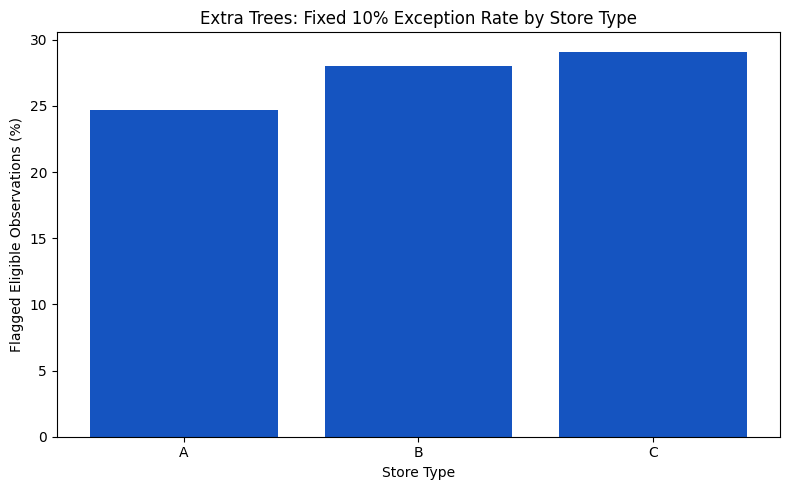

In [34]:

# ============================================================
# STORE TYPE A / B / C COMPARISON
# ============================================================

type_comparison = (
    eligible
    .groupby("Type")
    .agg(
        Eligible_Observations=("Flag_10pct_Markdown", "size"),
        Flagged_Exceptions=("Flag_10pct_Markdown", "sum"),
        Total_Dollar_Shortfall=(
            "Dollar_Shortfall",
            lambda x: x[eligible.loc[x.index, "Flag_10pct_Markdown"]].sum()
        )
    )
    .reset_index()
)

type_comparison["Flag_Rate_Pct"] = (
    100 * type_comparison["Flagged_Exceptions"]
    / type_comparison["Eligible_Observations"]
)

print("EXCEPTIONS BY STORE TYPE")
display(type_comparison.round(2))

# Chart: compare flag rates
plt.figure(figsize=(8, 5))

plt.bar(
    type_comparison["Type"],
    type_comparison["Flag_Rate_Pct"],
    color="#1554C0"
)

plt.title("Extra Trees: Fixed 10% Exception Rate by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Flagged Eligible Observations (%)")

plt.tight_layout()
plt.show()

type_comparison.to_csv(
    os.path.join(
        output_dir, "extra_trees_10pct_store_types.csv"
    ),
    index=False
)


TOP 15 DEPARTMENTS BY TOTAL FLAGGED SHORTFALL


,Dept,Flagged_Weeks,Stores_Affected,Total_Dollar_Shortfall,Average_Shortfall_Pct
2,3,222,45,1232368.04,28.39
36,38,125,45,1055865.93,15.18
55,72,148,40,919155.29,22.20
14,16,372,45,865823.36,23.85
8,9,231,45,810673.16,26.42
10,11,243,45,658868.73,21.03
6,7,251,45,609902.41,20.26
4,5,218,44,546728.17,22.26
21,23,152,41,502408.35,23.95
69,95,41,22,409381.15,12.54


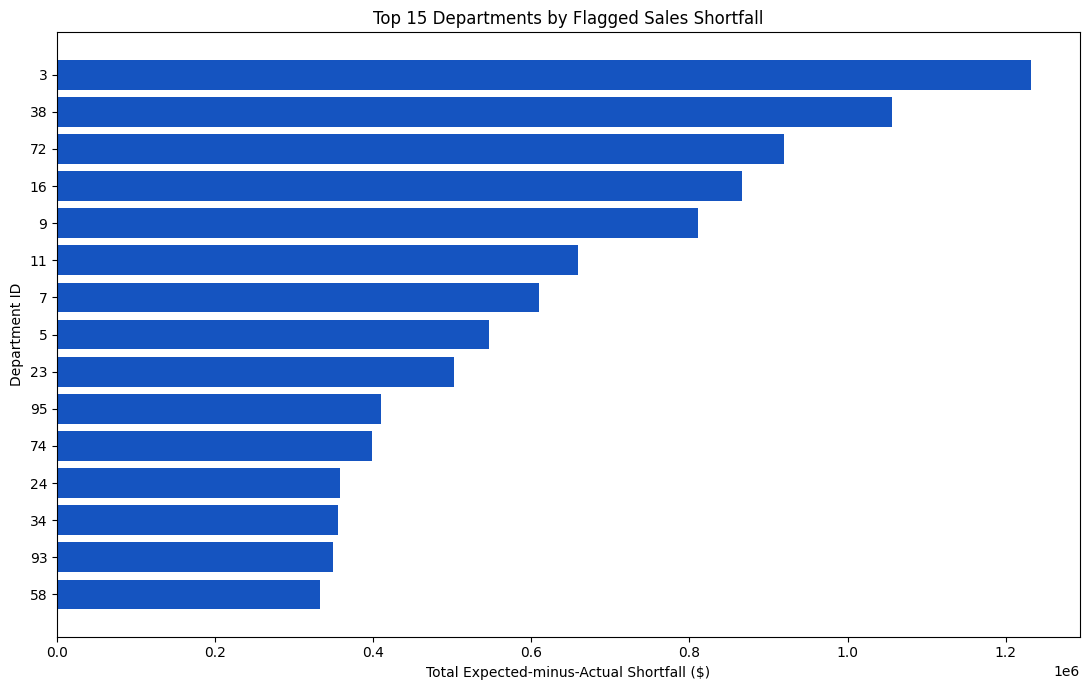

In [35]:

# ============================================================
# DEPARTMENT-LEVEL EXCEPTION SUMMARY
# ============================================================

dept_summary = (
    flagged
    .groupby("Dept")
    .agg(
        Flagged_Weeks=("Date", "size"),
        Stores_Affected=("Store", "nunique"),
        Total_Dollar_Shortfall=("Dollar_Shortfall", "sum"),
        Average_Shortfall_Pct=("Shortfall_Pct", "mean")
    )
    .reset_index()
    .sort_values(
        "Total_Dollar_Shortfall",
        ascending=False
    )
)

print("TOP 15 DEPARTMENTS BY TOTAL FLAGGED SHORTFALL")
display(dept_summary.head(15).round(2))

# Visualization
top15 = dept_summary.head(15).sort_values(
    "Total_Dollar_Shortfall"
)

plt.figure(figsize=(11, 7))

plt.barh(
    top15["Dept"].astype(str),
    top15["Total_Dollar_Shortfall"],
    color="#1554C0"
)

plt.title("Top 15 Departments by Flagged Sales Shortfall")
plt.xlabel("Total Expected-minus-Actual Shortfall ($)")
plt.ylabel("Department ID")

plt.tight_layout()
plt.show()

dept_summary.to_csv(
    os.path.join(
        output_dir, "extra_trees_10pct_department_summary.csv"
    ),
    index=False
)


**Store 7, Department 72 — Department-Level Case Study**

**Objective:** Examine weekly sales performance for Department 72 in Store 7 and identify potential sales exceptions using Extra Trees predictions.

**Methodology:**
- Compare actual weekly department sales with expected sales predicted by Extra Trees.
- Calculate percentage and dollar shortfalls for each week.
- Apply the fixed 10% shortfall threshold during weeks with recorded store-level markdown information.
- Visualize flagged exceptions to identify when significant sales declines occurred.

**Key Finding:** The updated Extra Trees model identified **4 flagged exceptions** for Store 7, Department 72, during July 20–October 26, 2012.

**Purpose:** Demonstrate how department-level detection can identify specific sales shortfalls and provide evidence for further business investigation and AI/RAG analysis.

**Note:** Recorded markdown information applies to the store-week, not necessarily to Department 72. These flags indicate potential exceptions, not confirmed markdown failures.

STORE 7 — DEPARTMENT 72
Flagged exceptions: 4


,Date,Actual_Sales,Expected_Sales,Dollar_Shortfall,Shortfall_Pct,Markdown_Recorded,Flag_10pct_Markdown
6672,2012-07-20,44919.81,42653.78,0.00,0.00,True,False
6673,2012-07-27,49791.93,44752.88,0.00,0.00,True,False
6674,2012-08-03,47099.32,47770.28,670.96,1.40,True,False
6675,2012-08-10,45011.58,45885.38,873.80,1.90,True,False
6676,2012-08-17,40291.02,44886.99,4595.97,10.24,True,True
6677,2012-08-24,33957.54,43905.59,9948.05,22.66,True,True
6678,2012-08-31,44585.30,37749.79,0.00,0.00,True,False
6679,2012-09-07,48408.77,46931.93,0.00,0.00,True,False
6680,2012-09-14,47807.13,44152.05,0.00,0.00,True,False
6681,2012-09-21,41184.89,45526.82,4341.93,9.54,True,False


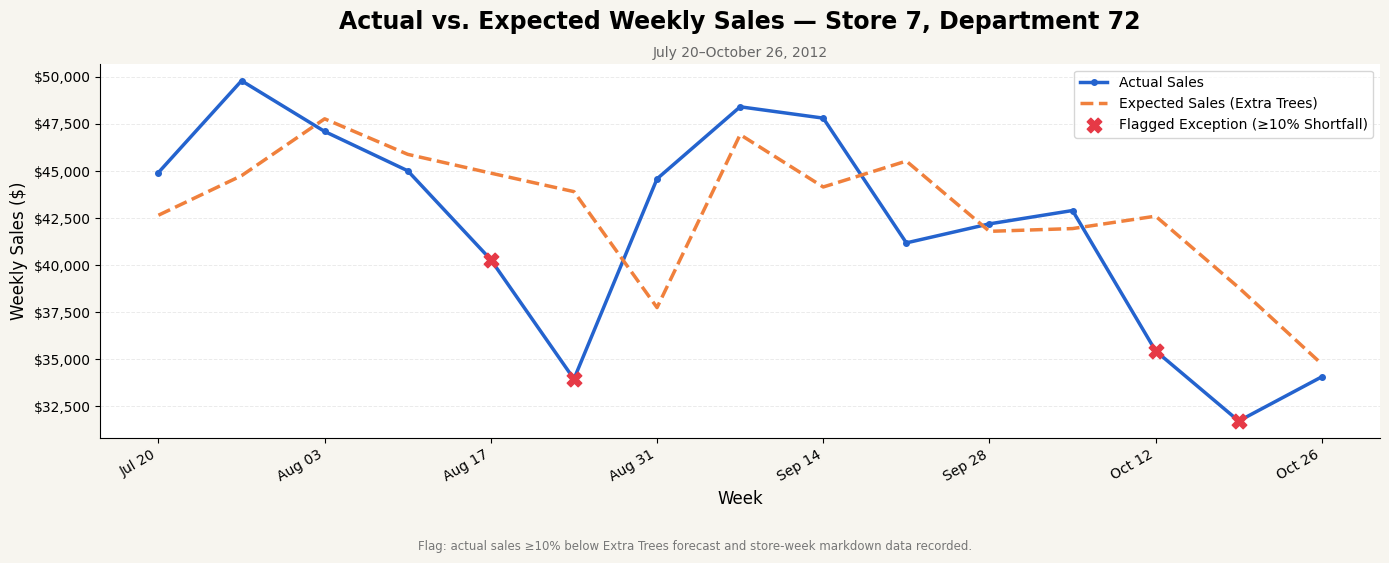

Chart saved to:
/content/store7_dept72_extra_trees_chart.png


In [36]:
# ============================================================
# STORE 7 — DEPARTMENT 72 CASE STUDY
# Presentation-ready visualization
# No inferred labels
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from IPython.display import display

# 1. Select Store 7, Department 72
case = et[
    (et["Store"] == 7) &
    (et["Dept"] == 72)
].sort_values("Date").copy()

case["Date"] = pd.to_datetime(case["Date"])

# Optional: restrict to presentation period only
case = case[
    (case["Date"] >= pd.Timestamp("2012-07-20")) &
    (case["Date"] <= pd.Timestamp("2012-10-26"))
].copy()

# 2. Identify flagged exceptions
# Must meet BOTH conditions:
#   - Sales shortfall >= 10%
#   - Markdown information recorded at store-week level
flagged_case = case[
    case["Flag_10pct_Markdown"]
].copy()

# 3. Display numerical results
print("STORE 7 — DEPARTMENT 72")
print("Flagged exceptions:", len(flagged_case))

display(
    case[
        [
            "Date",
            "Actual_Sales",
            "Expected_Sales",
            "Dollar_Shortfall",
            "Shortfall_Pct",
            "Markdown_Recorded",
            "Flag_10pct_Markdown"
        ]
    ].round(2)
)

# 4. Create visualization
fig, ax = plt.subplots(figsize=(14, 6))

fig.patch.set_facecolor("#F7F5EF")
ax.set_facecolor("white")

# Actual sales — blue solid line
ax.plot(
    case["Date"],
    case["Actual_Sales"],
    color="#2463CE",
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="Actual Sales",
    zorder=2
)

# Expected sales — orange dashed line
ax.plot(
    case["Date"],
    case["Expected_Sales"],
    color="#F0803C",
    linewidth=2.5,
    linestyle="--",
    label="Expected Sales (Extra Trees)",
    zorder=2
)

# Flagged exceptions — red X markers
ax.scatter(
    flagged_case["Date"],
    flagged_case["Actual_Sales"],
    color="#E63946",
    marker="X",
    s=110,
    label="Flagged Exception (≥10% Shortfall)",
    zorder=5
)

# 5. Titles
ax.set_title(
    "Actual vs. Expected Weekly Sales — Store 7, Department 72",
    fontsize=17,
    fontweight="bold",
    pad=25
)

# Clean subtitle — no inferred wording
ax.text(
    0.5, 1.01,
    "July 20–October 26, 2012",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=10,
    color="#666666"
)

# 6. Axis formatting
ax.set_xlabel("Week", fontsize=12)
ax.set_ylabel("Weekly Sales ($)", fontsize=12)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x:,.0f}")
)

ax.xaxis.set_major_locator(
    mdates.WeekdayLocator(byweekday=mdates.FR, interval=2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %d")
)

plt.setp(
    ax.get_xticklabels(),
    rotation=30,
    ha="right"
)

# 7. Grid and borders
ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    loc="upper right",
    frameon=True,
    fontsize=10
)

# 8. Explanation under graph
fig.text(
    0.5, 0.015,
    "Flag: actual sales ≥10% below Extra Trees forecast "
    "and store-week markdown data recorded.",
    ha="center",
    fontsize=8.5,
    color="#777777"
)

# 9. Save high-resolution image
plt.tight_layout(rect=[0, 0.06, 1, 0.94])

plt.savefig(
    "/content/store7_dept72_extra_trees_chart.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Chart saved to:")
print("/content/store7_dept72_extra_trees_chart.png")

STORE 7 — AUGUST 24, 2012
TOP 5 DEPARTMENTS BY PREDICTED SALES SHORTFALL


,Dept,Actual_Sales,Expected_Sales,Dollar_Shortfall,Shortfall_Pct,Flag_10pct_Markdown
6677,72,33957.54,43905.59,9948.05,22.66,True
6887,95,41387.24,44955.61,3568.37,7.94,False
6464,38,30998.54,34001.74,3003.20,8.83,False
6554,48,107.00,3074.42,2967.42,96.52,True
6812,90,14960.62,17113.39,2152.77,12.58,True


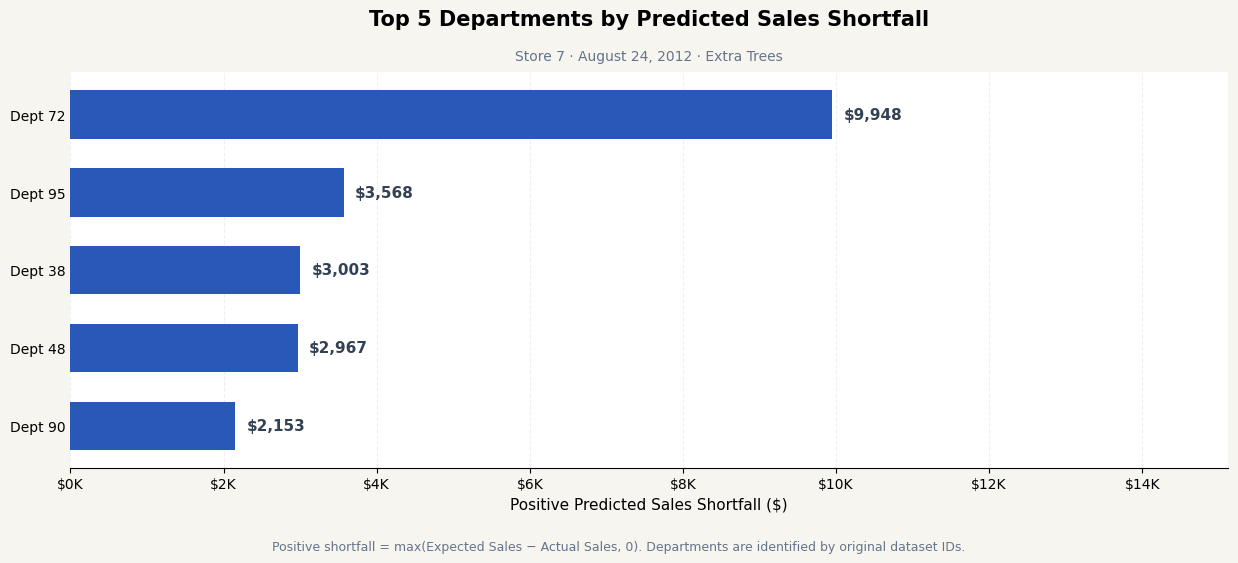

In [37]:

# ============================================================
# DEPARTMENT-LEVEL SHORTFALL DRILL-DOWN
# Store 7 | August 24, 2012 | Extra Trees
# Original Department IDs Only — No Inferred Mappings
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

# ------------------------------------------------------------
# 1. SELECT STORE 7 AND CASE DATE
# ------------------------------------------------------------

STORE_ID = 7
CASE_DATE = pd.Timestamp("2012-08-24")

case_depts = et[
    (et["Store"] == STORE_ID) &
    (pd.to_datetime(et["Date"]) == CASE_DATE)
].copy()

if case_depts.empty:
    raise ValueError("No Extra Trees predictions found for this case.")

# ------------------------------------------------------------
# 2. CALCULATE DEPARTMENT SHORTFALLS
# ------------------------------------------------------------

case_depts = case_depts[
    np.isfinite(case_depts["Expected_Sales"]) &
    (case_depts["Expected_Sales"] > 0)
].copy()

case_depts["Dollar_Shortfall"] = (
    case_depts["Expected_Sales"] -
    case_depts["Actual_Sales"]
).clip(lower=0)

case_depts["Shortfall_Pct"] = (
    100 * case_depts["Dollar_Shortfall"] /
    case_depts["Expected_Sales"]
)

case_depts["Department_Label"] = (
    "Dept " + case_depts["Dept"].astype(int).astype(str)
)

# ------------------------------------------------------------
# 3. SELECT TOP 5 BY DOLLAR SHORTFALL
# ------------------------------------------------------------

top5 = (
    case_depts[case_depts["Dollar_Shortfall"] > 0]
    .nlargest(5, "Dollar_Shortfall")
    .sort_values("Dollar_Shortfall")
    .copy()
)

print("STORE 7 — AUGUST 24, 2012")
print("TOP 5 DEPARTMENTS BY PREDICTED SALES SHORTFALL")

display(
    top5[
        [
            "Dept", "Actual_Sales",
            "Expected_Sales", "Dollar_Shortfall",
            "Shortfall_Pct", "Flag_10pct_Markdown"
        ]
    ]
    .sort_values("Dollar_Shortfall", ascending=False)
    .round(2)
)

# ------------------------------------------------------------
# 4. CREATE PRESENTATION-READY CHART
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 6.5))

fig.patch.set_facecolor("#F7F5EF")
ax.set_facecolor("white")

bars = ax.barh(
    top5["Department_Label"],
    top5["Dollar_Shortfall"],
    color="#2858B8",
    height=0.62
)

max_value = top5["Dollar_Shortfall"].max()

# Add dollar values
for bar in bars:
    value = bar.get_width()
    ax.text(
        value + max_value * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"${value:,.0f}",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#334155"
    )

ax.set_xlim(0, max_value * 1.52)

# ------------------------------------------------------------
# 5. TITLES
# ------------------------------------------------------------

ax.set_title(
    "Top 5 Departments by Predicted Sales Shortfall",
    fontsize=15,
    fontweight="bold",
    pad=34
)

ax.text(
    0.5, 1.03,
    "Store 7 · August 24, 2012 · Extra Trees",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    color="#64748B"
)

ax.set_xlabel(
    "Positive Predicted Sales Shortfall ($)",
    fontsize=11
)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x/1000:,.0f}K")
)

# ------------------------------------------------------------
# 6. HIGHLIGHT DEPARTMENT 72 IF IN TOP 5
# ------------------------------------------------------------

if 72 in top5["Dept"].values:

    dept72 = top5[top5["Dept"] == 72].iloc[0]
    dept72_position = list(top5["Dept"]).index(72)



# ------------------------------------------------------------
# 7. FORMATTING
# ------------------------------------------------------------

ax.grid(axis="x", linestyle="--", alpha=0.18)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y", length=0)

fig.text(
    0.5, 0.045,
    "Positive shortfall = max(Expected Sales − Actual Sales, 0). "
    "Departments are identified by original dataset IDs.",
    ha="center",
    fontsize=9,
    color="#64748B"
)

plt.tight_layout(rect=[0.02, 0.08, 0.98, 0.90])

# ------------------------------------------------------------
# 8. SAVE CHART
# ------------------------------------------------------------

plt.savefig(
    "/content/store7_department_drilldown.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


**Store 7 — Aggregated Extra Trees Forecast (Eligible Departments)**


**Objective:** Evaluate whether Store 7 shows an overall sales shortfall by aggregating predictions from the selected Extra Trees department-level forecasting model.

**Methodology:**
- Aggregate actual and expected weekly sales across eligible departments within Store 7.
- Calculate the percentage and dollar difference between expected and actual sales.
- Apply the fixed 10% shortfall threshold to identify potential store-level exceptions during weeks with recorded markdown data.
- Compare store-level results with department-level exceptions to identify shortfalls that may be hidden in overall store performance.

**Important:** This is an aggregation of department-level Extra Trees forecasts, not a separately trained store-level model. Only departments with eligible predictions are included.

**Purpose:** Determine whether overall store performance and department-level performance tell the same story before prioritizing exceptions for AI/RAG investigation.

STORE 7 — DEPARTMENT COVERAGE


,Date,Departments_Included,Total_Observed_Departments,Coverage_Pct
0,2012-07-20,65,68,95.59
1,2012-07-27,66,68,97.06
2,2012-08-03,66,69,95.65
3,2012-08-10,66,67,98.51
4,2012-08-17,65,66,98.48
5,2012-08-24,65,68,95.59
6,2012-08-31,65,69,94.20
7,2012-09-07,65,69,94.20
8,2012-09-14,65,69,94.20
9,2012-09-21,65,69,94.20


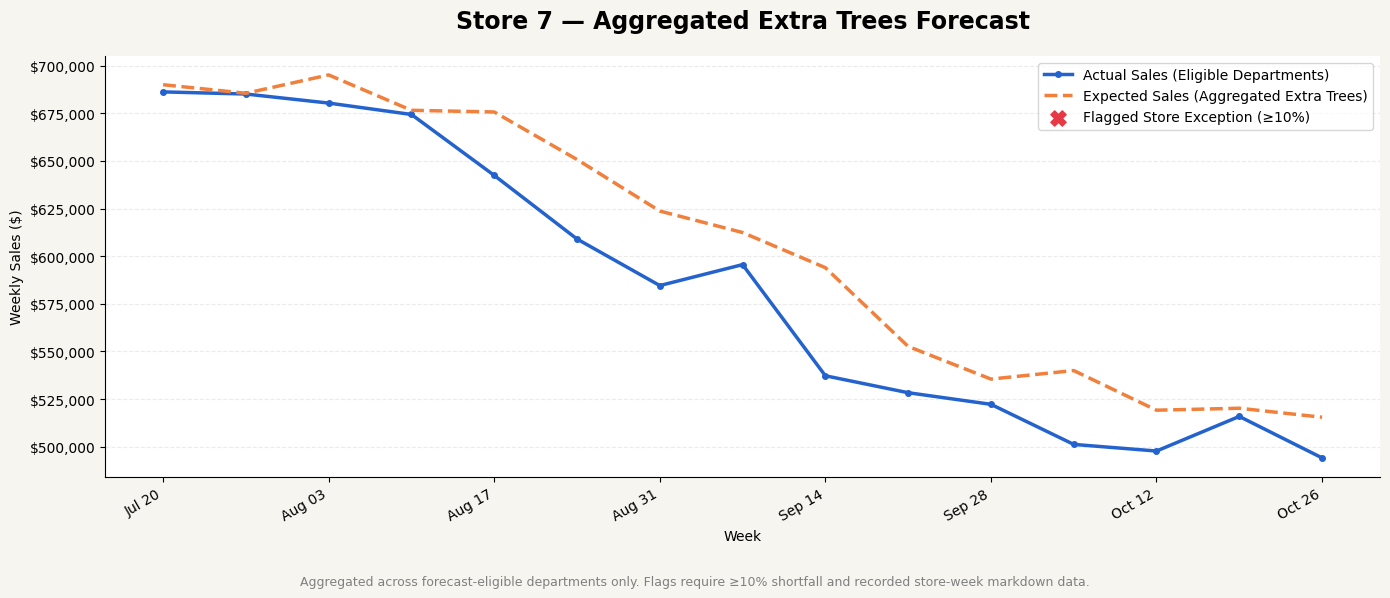

In [38]:

# ============================================================
# STORE 7 — STORE-LEVEL EXTRA TREES ANALYSIS
# Aggregated Department Predictions | Fixed 10%
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from IPython.display import display

output_dir = "/content/walmart_model_comparison"
os.makedirs(output_dir, exist_ok=True)

# 1. Select Store 7 and valid forecast baselines
store7_dept = et[
    (et["Store"] == 7) &
    et["Valid_Baseline"]
].copy()

store7_dept["Date"] = pd.to_datetime(store7_dept["Date"])

assert not store7_dept.empty, "No valid Store 7 predictions found."

# 2. Aggregate the same eligible departments
# for actual and expected sales
store7_week = (
    store7_dept
    .groupby("Date", as_index=False)
    .agg(
        Actual_Sales=("Actual_Sales", "sum"),
        Expected_Sales=("Expected_Sales", "sum"),
        Departments_Included=("Dept", "nunique"),
        Markdown_Recorded=("Markdown_Recorded", "max")
    )
    .sort_values("Date")
)

# 3. Store-level shortfall
store7_week["Dollar_Shortfall"] = (
    store7_week["Expected_Sales"] -
    store7_week["Actual_Sales"]
).clip(lower=0)

store7_week["Shortfall_Pct"] = (
    100 * store7_week["Dollar_Shortfall"] /
    store7_week["Expected_Sales"]
)

# 4. Fixed 10% anomaly rule
store7_week["Store_Flag_10pct"] = (
    (store7_week["Shortfall_Pct"] >= 10) &
    store7_week["Markdown_Recorded"]
)


# ------------------------------------------------------------
# 5. Compare forecast coverage with original sales data
# ------------------------------------------------------------

# 'sales' contains original train.csv observations,
# before departments were excluded by lag requirements.
raw_store7 = sales[sales["Store"] == 7].copy()
raw_store7["Date"] = pd.to_datetime(raw_store7["Date"])

raw_coverage = (
    raw_store7.groupby("Date")["Dept"]
    .nunique()
    .rename("Total_Observed_Departments")
    .reset_index()
)

store7_week = store7_week.merge(
    raw_coverage,
    on="Date",
    how="left",
    validate="one_to_one"
)

store7_week["Coverage_Pct"] = (
    100 * store7_week["Departments_Included"]
    / store7_week["Total_Observed_Departments"]
)

print("STORE 7 — DEPARTMENT COVERAGE")

display(
    store7_week[
        [
            "Date",
            "Departments_Included",
            "Total_Observed_Departments",
            "Coverage_Pct"
        ]
    ].round(2)
)

assert (
    store7_week["Departments_Included"]
    <= store7_week["Total_Observed_Departments"]
).all(), "Forecast coverage exceeds observed department count."


# 6. Presentation chart
flags = store7_week[store7_week["Store_Flag_10pct"]]

fig, ax = plt.subplots(figsize=(14, 6))
fig.patch.set_facecolor("#F7F5EF")
ax.set_facecolor("white")

ax.plot(
    store7_week["Date"],
    store7_week["Actual_Sales"],
    color="#2463CE",
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="Actual Sales (Eligible Departments)"
)

ax.plot(
    store7_week["Date"],
    store7_week["Expected_Sales"],
    color="#F0803C",
    linewidth=2.5,
    linestyle="--",
    label="Expected Sales (Aggregated Extra Trees)"
)

ax.scatter(
    flags["Date"],
    flags["Actual_Sales"],
    color="#E63946",
    marker="X",
    s=120,
    zorder=5,
    label="Flagged Store Exception (≥10%)"
)

ax.set_title(
    "Store 7 — Aggregated Extra Trees Forecast",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Week")
ax.set_ylabel("Weekly Sales ($)")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"${x:,.0f}")
)

ax.xaxis.set_major_locator(
    mdates.WeekdayLocator(byweekday=mdates.FR, interval=2)
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %d")
)

plt.xticks(rotation=30, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="best")

fig.text(
    0.5, 0.015,
    "Aggregated across forecast-eligible departments only. "
    "Flags require ≥10% shortfall and recorded store-week markdown data.",
    ha="center",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

plt.savefig(
    f"{output_dir}/store7_aggregated_forecast.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


In [39]:

# ============================================================
# STORE 7 — DEPARTMENT EXCEPTION INVESTIGATION
# ============================================================

# 1. Join store-level results back to departments
investigation = store7_dept.merge(
    store7_week[
        ["Date", "Store_Flag_10pct", "Shortfall_Pct"]
    ].rename(columns={
        "Shortfall_Pct": "Store_Shortfall_Pct"
    }),
    on="Date",
    how="left",
    validate="many_to_one"
)

# 2. Department-level flags remain independent
investigation["Department_Flag_10pct"] = (
    investigation["Flag_10pct_Markdown"]
)

# 3. Department flags during unflagged store-weeks
hidden_dept_exceptions = investigation[
    investigation["Department_Flag_10pct"] &
    ~investigation["Store_Flag_10pct"]
].copy()

print("DEPARTMENT EXCEPTIONS WHEN STORE 7 IS NOT FLAGGED")
print("Number of hidden department exceptions:",
      len(hidden_dept_exceptions))

hidden_table = (
    hidden_dept_exceptions[
        [
            "Date", "Dept",
            "Actual_Sales", "Expected_Sales",
            "Dollar_Shortfall", "Shortfall_Pct",
            "Store_Shortfall_Pct"
        ]
    ]
    .sort_values(
        ["Date", "Dollar_Shortfall"],
        ascending=[True, False]
    )
)

display(hidden_table.head(30).round(2))

# 4. Rank department shortfalls for every week
ranking = investigation[
    investigation["Dollar_Shortfall"] > 0
].copy()

ranking["Department_Rank"] = (
    ranking.groupby("Date")["Dollar_Shortfall"]
    .rank(method="first", ascending=False)
)

top_departments = (
    ranking[ranking["Department_Rank"] <= 5]
    .sort_values(["Date", "Department_Rank"])
    .copy()
)

print("\nTOP 5 DEPARTMENT SHORTFALLS FOR EACH WEEK")

display(
    top_departments[
        [
            "Date", "Dept",
            "Dollar_Shortfall", "Shortfall_Pct",
            "Store_Flag_10pct",
            "Department_Flag_10pct"
        ]
    ].round(2)
)

# 5. Save results
store7_week.to_csv(
    f"{output_dir}/store7_aggregated_forecast.csv",
    index=False
)

hidden_table.to_csv(
    f"{output_dir}/store7_hidden_department_exceptions.csv",
    index=False
)

top_departments.to_csv(
    f"{output_dir}/store7_top5_department_shortfalls_by_week.csv",
    index=False
)

print("\nStore 7 investigation files saved.")


DEPARTMENT EXCEPTIONS WHEN STORE 7 IS NOT FLAGGED
Number of hidden department exceptions: 327


,Date,Dept,Actual_Sales,Expected_Sales,Dollar_Shortfall,Shortfall_Pct,Store_Shortfall_Pct
498,2012-07-20,38,29902.48,37742.70,7840.22,20.77,0.55
651,2012-07-20,56,9486.31,14651.16,5164.85,35.25,0.55
681,2012-07-20,67,3826.86,4707.74,880.88,18.71,0.55
318,2012-07-20,25,5972.28,6707.48,735.20,10.96,0.55
906,2012-07-20,94,972.27,1530.35,558.08,36.47,0.55
696,2012-07-20,71,1800.56,2202.48,401.92,18.25,0.55
303,2012-07-20,24,1900.82,2268.62,367.80,16.21,0.55
483,2012-07-20,36,1049.00,1383.16,334.16,24.16,0.55
936,2012-07-20,96,1563.57,1871.67,308.10,16.46,0.55
468,2012-07-20,35,131.76,191.29,59.53,31.12,0.55



TOP 5 DEPARTMENT SHORTFALLS FOR EACH WEEK


,Date,Dept,Dollar_Shortfall,Shortfall_Pct,Store_Flag_10pct,Department_Flag_10pct
498,2012-07-20,38,7840.22,20.77,False,True
651,2012-07-20,56,5164.85,35.25,False,True
573,2012-07-20,46,1504.45,7.32,False,False
150,2012-07-20,11,1432.81,8.36,False,False
726,2012-07-20,74,1073.04,8.91,False,False
...,...,...,...,...,...,...
134,2012-10-26,9,15166.74,41.55,False,True
512,2012-10-26,38,2946.36,10.07,False,True
740,2012-10-26,74,1577.17,15.62,False,True
557,2012-10-26,42,1536.86,21.60,False,True



Store 7 investigation files saved.


In [40]:

# ============================================================
# STORE 7 — FORMATTED INVESTIGATION TABLES
# ============================================================

print("TABLE 1 — HIDDEN DEPARTMENT EXCEPTIONS")

display(
    hidden_table.head(30).style
    .format({
        "Date": lambda x: pd.Timestamp(x).strftime("%b %d, %Y"),
        "Actual_Sales": "${:,.0f}",
        "Expected_Sales": "${:,.0f}",
        "Dollar_Shortfall": "${:,.0f}",
        "Shortfall_Pct": "{:.1f}%",
        "Store_Shortfall_Pct": "{:.1f}%"
    })
    .background_gradient(
        subset=["Dollar_Shortfall"],
        cmap="Blues"
    )
)

print("\nTABLE 2 — TOP FIVE DEPARTMENT SHORTFALLS PER WEEK")

display(
    top_departments[
        [
            "Date", "Dept", "Dollar_Shortfall",
            "Shortfall_Pct",
            "Store_Flag_10pct",
            "Department_Flag_10pct"
        ]
    ].style
    .format({
        "Date": lambda x: pd.Timestamp(x).strftime("%b %d, %Y"),
        "Dollar_Shortfall": "${:,.0f}",
        "Shortfall_Pct": "{:.1f}%"
    })
    .background_gradient(
        subset=["Dollar_Shortfall"],
        cmap="Blues"
    )
)


TABLE 1 — HIDDEN DEPARTMENT EXCEPTIONS


,Date,Dept,Actual_Sales,Expected_Sales,Dollar_Shortfall,Shortfall_Pct,Store_Shortfall_Pct
498,"Jul 20, 2012",38,"$29,902","$37,743","$7,840",20.8%,0.5%
651,"Jul 20, 2012",56,"$9,486","$14,651","$5,165",35.3%,0.5%
681,"Jul 20, 2012",67,"$3,827","$4,708",$881,18.7%,0.5%
318,"Jul 20, 2012",25,"$5,972","$6,707",$735,11.0%,0.5%
906,"Jul 20, 2012",94,$972,"$1,530",$558,36.5%,0.5%
696,"Jul 20, 2012",71,"$1,801","$2,202",$402,18.2%,0.5%
303,"Jul 20, 2012",24,"$1,901","$2,269",$368,16.2%,0.5%
483,"Jul 20, 2012",36,"$1,049","$1,383",$334,24.2%,0.5%
936,"Jul 20, 2012",96,"$1,564","$1,872",$308,16.5%,0.5%
468,"Jul 20, 2012",35,$132,$191,$60,31.1%,0.5%



TABLE 2 — TOP FIVE DEPARTMENT SHORTFALLS PER WEEK


,Date,Dept,Dollar_Shortfall,Shortfall_Pct,Store_Flag_10pct,Department_Flag_10pct
498,"Jul 20, 2012",38,"$7,840",20.8%,False,True
651,"Jul 20, 2012",56,"$5,165",35.3%,False,True
573,"Jul 20, 2012",46,"$1,504",7.3%,False,False
150,"Jul 20, 2012",11,"$1,433",8.4%,False,False
726,"Jul 20, 2012",74,"$1,073",8.9%,False,False
652,"Jul 27, 2012",56,"$5,085",56.4%,False,True
121,"Jul 27, 2012",9,"$1,774",3.3%,False,False
289,"Jul 27, 2012",23,"$1,412",9.5%,False,False
574,"Jul 27, 2012",46,"$1,279",6.6%,False,False
877,"Jul 27, 2012",92,"$1,018",3.0%,False,False


In [41]:

# ============================================================
# STORE 7 — BASELINE VERIFICATION
# ============================================================

print("STORE 7 BASELINE CHECK")
print("=" * 50)

print("Test weeks:", store7_week["Date"].nunique())

print("Store-level flagged weeks:",
      store7_week["Store_Flag_10pct"].sum())

print("Department-level flagged observations:",
      investigation["Department_Flag_10pct"].sum())

print("Department flags in unflagged store-weeks:",
      len(hidden_dept_exceptions))

print("Weeks with hidden department exceptions:",
      hidden_dept_exceptions["Date"].nunique())

print("\nDepartment coverage range:",
      store7_week["Departments_Included"].min(),
      "to",
      store7_week["Departments_Included"].max())

print("\nSaved files:")
for name in sorted(os.listdir(output_dir)):
    if name.startswith("store7_"):
        print(name)


STORE 7 BASELINE CHECK
Test weeks: 15
Store-level flagged weeks: 0
Department-level flagged observations: 327
Department flags in unflagged store-weeks: 327
Weeks with hidden department exceptions: 15

Department coverage range: 65 to 66

Saved files:
store7_aggregated_forecast.csv
store7_aggregated_forecast.png
store7_hidden_department_exceptions.csv
store7_top5_department_shortfalls_by_week.csv


**2. Dynamic Threshold Evaluation**

Historical Percentiles and MAD

In [42]:

# ============================================================
# DYNAMIC THRESHOLDS — STEP 1
# Historical Out-of-Sample Extra Trees Predictions
# ============================================================

import os
import numpy as np
import pandas as pd
from IPython.display import display

output_dir = "/content/walmart_model_comparison"
os.makedirs(output_dir, exist_ok=True)

history_path = os.path.join(
    output_dir, "extra_trees_validation_predictions.csv"
)

# Reuse saved historical predictions if already generated
if os.path.exists(history_path):
    historical_et = pd.read_csv(
        history_path, parse_dates=["Date"]
    )
    print("Loaded saved historical predictions.")

else:
    validation_frames = []

    for fold_name, start, end in validation_periods:

        train_fold = model_df[
            model_df["Date"] < pd.Timestamp(start)
        ]

        valid_fold = model_df[
            model_df["Date"].between(start, end)
        ].copy()

        # Same Extra Trees definition as model comparison
        model = get_models()["Extra Trees"]

        print("Training:", fold_name, flush=True)

        model.fit(
            train_fold[feature_cols],
            train_fold["Weekly_Sales"]
        )

        valid_fold["Expected_Sales"] = model.predict(
            valid_fold[feature_cols]
        )

        valid_fold["Period"] = fold_name

        validation_frames.append(
            valid_fold[
                [
                    "Store", "Dept", "Date", "Type",
                    "Weekly_Sales", "Expected_Sales",
                    "Period"
                ]
            ]
        )

        print("Finished:", fold_name, flush=True)

    historical_et = pd.concat(
        validation_frames, ignore_index=True
    )

    historical_et.to_csv(history_path, index=False)
    print("Historical predictions saved.")

# Add markdown context from original data
markdown_cols = [f"MarkDown{i}" for i in range(1, 6)]

markdown_history = features_data[
    ["Store", "Date"] + markdown_cols
].copy()

markdown_history["Date"] = pd.to_datetime(
    markdown_history["Date"]
)

assert not markdown_history.duplicated(
    ["Store", "Date"]
).any(), "Duplicate Store-Date records in features.csv."

markdown_history["Markdown_Recorded"] = (
    markdown_history[markdown_cols].notna().any(axis=1)
)

historical_et = historical_et.drop(
    columns=["Markdown_Recorded"], errors="ignore"
)

historical_et = historical_et.merge(
    markdown_history[
        ["Store", "Date", "Markdown_Recorded"]
    ],
    on=["Store", "Date"],
    how="left",
    validate="many_to_one"
)

historical_et["Markdown_Recorded"] = (
    historical_et["Markdown_Recorded"]
    .fillna(False).astype(bool)
)

# Calculate signed residual percentage
# Negative = actual sales below expected
historical_et["Residual_Pct"] = np.where(
    historical_et["Expected_Sales"] > 0,
    100 * (
        historical_et["Weekly_Sales"]
        - historical_et["Expected_Sales"]
    ) / historical_et["Expected_Sales"],
    np.nan
)

# One-sided downside error in percentage points
historical_et["Shortfall_Pct"] = (
    -historical_et["Residual_Pct"]
).clip(lower=0)

# Only use observations with valid expected sales
# and recorded store-week markdown information.
calibration = historical_et[
    (historical_et["Expected_Sales"] > 0)
    & np.isfinite(historical_et["Residual_Pct"])
    & historical_et["Markdown_Recorded"]
].copy()

assert len(calibration) > 0, (
    "No eligible historical observations for calibration."
)

print("\nHISTORICAL CALIBRATION SUMMARY")
print("Eligible observations:", len(calibration))

display(
    calibration.groupby("Period").agg(
        Observations=("Shortfall_Pct", "size"),
        Median_Shortfall=("Shortfall_Pct", "median"),
        Mean_Shortfall=("Shortfall_Pct", "mean")
    ).round(2)
)

calibration.to_csv(
    os.path.join(output_dir, "threshold_calibration_data.csv"),
    index=False
)


Training: Validation 1
Finished: Validation 1
Training: Validation 2
Finished: Validation 2
Training: Validation 3
Finished: Validation 3
Historical predictions saved.

HISTORICAL CALIBRATION SUMMARY
Eligible observations: 94243


,Observations,Median_Shortfall,Mean_Shortfall
Period,,,
Validation 1,31550,4.39,11.19
Validation 2,31493,3.60,9.19
Validation 3,31200,1.69,7.80


In [43]:

# ============================================================
# DYNAMIC THRESHOLDS — STEP 2
# Fixed 10% vs Historical P90 / P95 / MAD
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

# 1. Historical percentile thresholds
p90 = calibration["Shortfall_Pct"].quantile(0.90)
p95 = calibration["Shortfall_Pct"].quantile(0.95)

# 2. Historical MAD threshold
# Based on SIGNED actual-minus-expected residuals
def mad_cutoff(residuals):
    residuals = pd.Series(residuals).dropna()

    median = residuals.median()
    mad = np.median(np.abs(residuals - median))

    # Lower-tail boundary in signed percentage points.
    lower_bound = median - 2 * mad

    # Convert to positive shortfall percentage.
    return max(0.0, -lower_bound)

global_mad = mad_cutoff(calibration["Residual_Pct"])

# 3. Type-specific MAD thresholds
MIN_CALIBRATION_ROWS = 100

type_thresholds = {}

for store_type in ["A", "B", "C"]:
    subset = calibration[
        calibration["Type"] == store_type
    ]

    if len(subset) >= MIN_CALIBRATION_ROWS:
        threshold = mad_cutoff(subset["Residual_Pct"])
    else:
        threshold = global_mad

    type_thresholds[store_type] = threshold

# Display threshold values
threshold_values = pd.DataFrame([
    ["Fixed 10%", 10.0],
    ["Historical P90", p90],
    ["Historical P95", p95],
    ["Global MAD", global_mad],
    ["Type A MAD", type_thresholds["A"]],
    ["Type B MAD", type_thresholds["B"]],
    ["Type C MAD", type_thresholds["C"]]
], columns=["Method", "Threshold_Pct"])

print("CALIBRATED THRESHOLDS")
display(threshold_values.round(2))

# 4. Apply thresholds to existing FINAL-TEST data
# 'et' comes from your fixed 10% detection section.
test = et[
    et["Valid_Baseline"]
    & et["Markdown_Recorded"]
].copy()

test["Flag_Fixed10"] = test["Shortfall_Pct"] >= 10
test["Flag_P90"] = (
    (test["Shortfall_Pct"] > 0)
    & (test["Shortfall_Pct"] >= p90)
)
test["Flag_P95"] = (
    (test["Shortfall_Pct"] > 0)
    & (test["Shortfall_Pct"] >= p95)
)
test["Flag_GlobalMAD"] = (
    (test["Shortfall_Pct"] > 0)
    & (test["Shortfall_Pct"] >= global_mad)
)

test["Type_MAD_Threshold"] = (
    test["Type"].map(type_thresholds)
)

test["Flag_TypeMAD"] = (
    (test["Shortfall_Pct"] > 0)
    & (
        test["Shortfall_Pct"]
        >= test["Type_MAD_Threshold"]
    )
)

# 5. Compare alert counts and shortfall impact
flag_columns = {
    "Fixed 10%": "Flag_Fixed10",
    "Historical P90": "Flag_P90",
    "Historical P95": "Flag_P95",
    "Global MAD": "Flag_GlobalMAD",
    "Type-Specific MAD": "Flag_TypeMAD"
}

results = []

for method, column in flag_columns.items():
    flagged_rows = test[test[column]]

    results.append({
        "Method": method,
        "Eligible_Observations": len(test),
        "Flagged_Observations": len(flagged_rows),
        "Flag_Rate_Pct": (
            100 * len(flagged_rows) / len(test)
        ),
        "Total_Flagged_Shortfall": (
            flagged_rows["Dollar_Shortfall"].sum()
        ),
        "Median_Flagged_Shortfall": (
            flagged_rows["Dollar_Shortfall"].median()
        )
    })

threshold_comparison = pd.DataFrame(results)

print("\nFINAL-TEST THRESHOLD COMPARISON")
display(threshold_comparison.round(2))

# 6. Break down alert rates by store type
type_results = []

for method, column in flag_columns.items():
    for store_type, group in test.groupby("Type"):
        type_results.append({
            "Method": method,
            "Type": store_type,
            "Eligible": len(group),
            "Flagged": int(group[column].sum()),
            "Flag_Rate_Pct": 100 * group[column].mean()
        })

threshold_by_type = pd.DataFrame(type_results)

print("\nTHRESHOLD COMPARISON BY STORE TYPE")
display(threshold_by_type.round(2))

# 7. Store 7, Department 72 comparison
case_comparison = test[
    (test["Store"] == 7)
    & (test["Dept"] == 72)
].sort_values("Date")

print("\nSTORE 7 — DEPARTMENT 72")
display(
    case_comparison[
        [
            "Date", "Actual_Sales", "Expected_Sales",
            "Dollar_Shortfall", "Shortfall_Pct",
            "Flag_Fixed10", "Flag_P90", "Flag_P95",
            "Flag_GlobalMAD", "Flag_TypeMAD"
        ]
    ].round(2)
)

# 8. Export results
threshold_values.to_csv(
    f"{output_dir}/dynamic_threshold_values.csv",
    index=False
)

threshold_comparison.to_csv(
    f"{output_dir}/dynamic_threshold_comparison.csv",
    index=False
)

threshold_by_type.to_csv(
    f"{output_dir}/dynamic_threshold_by_store_type.csv",
    index=False
)

test.to_csv(
    f"{output_dir}/dynamic_threshold_test_predictions.csv",
    index=False
)

print("\nDynamic threshold comparison complete.")


CALIBRATED THRESHOLDS


,Method,Threshold_Pct
0,Fixed 10%,10.00
1,Historical P90,26.60
2,Historical P95,38.59
3,Global MAD,22.36
4,Type A MAD,21.07
5,Type B MAD,23.96
6,Type C MAD,23.04



FINAL-TEST THRESHOLD COMPARISON


,Method,Eligible_Observations,Flagged_Observations,Flag_Rate_Pct,Total_Flagged_Shortfall,Median_Flagged_Shortfall
0,Fixed 10%,42400,11207,26.43,17837181.38,719.70
1,Historical P90,42400,3360,7.92,4598878.94,391.14
2,Historical P95,42400,1726,4.07,2375746.67,213.33
3,Global MAD,42400,4365,10.29,6216159.38,461.44
4,Type-Specific MAD,42400,4381,10.33,6297746.30,473.90



THRESHOLD COMPARISON BY STORE TYPE


,Method,Type,Eligible,Flagged,Flag_Rate_Pct
0,Fixed 10%,A,21791,5385,24.71
1,Fixed 10%,B,16424,4604,28.03
2,Fixed 10%,C,4185,1218,29.10
3,Historical P90,A,21791,1454,6.67
4,Historical P90,B,16424,1308,7.96
5,Historical P90,C,4185,598,14.29
6,Historical P95,A,21791,678,3.11
7,Historical P95,B,16424,661,4.02
8,Historical P95,C,4185,387,9.25
9,Global MAD,A,21791,1932,8.87



STORE 7 — DEPARTMENT 72


,Date,Actual_Sales,Expected_Sales,Dollar_Shortfall,Shortfall_Pct,Flag_Fixed10,Flag_P90,Flag_P95,Flag_GlobalMAD,Flag_TypeMAD
6672,2012-07-20,44919.81,42653.78,0.00,0.00,False,False,False,False,False
6673,2012-07-27,49791.93,44752.88,0.00,0.00,False,False,False,False,False
6674,2012-08-03,47099.32,47770.28,670.96,1.40,False,False,False,False,False
6675,2012-08-10,45011.58,45885.38,873.80,1.90,False,False,False,False,False
6676,2012-08-17,40291.02,44886.99,4595.97,10.24,True,False,False,False,False
6677,2012-08-24,33957.54,43905.59,9948.05,22.66,True,False,False,True,False
6678,2012-08-31,44585.30,37749.79,0.00,0.00,False,False,False,False,False
6679,2012-09-07,48408.77,46931.93,0.00,0.00,False,False,False,False,False
6680,2012-09-14,47807.13,44152.05,0.00,0.00,False,False,False,False,False
6681,2012-09-21,41184.89,45526.82,4341.93,9.54,False,False,False,False,False



Dynamic threshold comparison complete.


P95 creates the smallest investigation workload, but it also excludes potentially important cases.

For example, Store 7, Department 72 experienced a $9,948 predicted sales shortfall (22.66%) on August 24, 2012.

P95 didn't flag it. Global MAD did.

That doesn't prove global MAD is better, but it raises an important question: Are we eliminating financially meaningful cases by choosing an overly strict percentage threshold?
2. Why global MAD is a reasonable starting point
Global MAD has three advantages for your project:
- Historically grounded: Its 22.36% threshold comes from earlier Extra Trees validation errors.
- Robust: MAD is less influenced by extreme observations than standard deviation.
- Simpler to explain: A single rule avoids introducing unnecessary complexity before establishing that store-specific thresholds help.
Your type-specific MAD approach flags almost the same total number of observations as global MAD, and the store types still have noticeably different flag rates.

So I don't see strong evidence yet that separate thresholds for Types A, B, and C justify the added complexity.

In [44]:
# Compare flags for Store 7, Department 72
case72 = test[
    (test["Store"] == 7) &
    (test["Dept"] == 72)
].copy()

methods = [
    "Flag_Fixed10",
    "Flag_P90",
    "Flag_P95",
    "Flag_GlobalMAD",
    "Flag_TypeMAD"
]

print("STORE 7, DEPARTMENT 72 — FLAG COUNTS")
display(case72[methods].sum().to_frame("Flagged_Weeks"))

print("\nWEEKS FLAGGED BY AT LEAST ONE METHOD")
display(
    case72.loc[
        case72[methods].any(axis=1),
        ["Date", "Actual_Sales", "Expected_Sales",
         "Dollar_Shortfall", "Shortfall_Pct"] + methods
    ].sort_values("Date").round(2)
)

STORE 7, DEPARTMENT 72 — FLAG COUNTS


,Flagged_Weeks
Flag_Fixed10,4
Flag_P90,0
Flag_P95,0
Flag_GlobalMAD,1
Flag_TypeMAD,0



WEEKS FLAGGED BY AT LEAST ONE METHOD


,Date,Actual_Sales,Expected_Sales,Dollar_Shortfall,Shortfall_Pct,Flag_Fixed10,Flag_P90,Flag_P95,Flag_GlobalMAD,Flag_TypeMAD
6676,2012-08-17,40291.02,44886.99,4595.97,10.24,True,False,False,False,False
6677,2012-08-24,33957.54,43905.59,9948.05,22.66,True,False,False,True,False
6684,2012-10-12,35449.75,42603.46,7153.71,16.79,True,False,False,False,False
6685,2012-10-19,31729.10,38809.28,7080.18,18.24,True,False,False,False,False


### Store 7, Department 72 — Dynamic Threshold Comparison

The fixed 10% threshold identified four weekly sales exceptions during the final-test period. In comparison, global MAD identified one exception, while historical P90, P95, and store-type-specific MAD identified none.

August 24, 2012 had the largest shortfall among these four weeks, with actual sales approximately $9,948 below Extra Trees predictions (22.66%). This observation exceeded the global MAD threshold of 22.36% but did not exceed the Type B MAD threshold of 23.96%.

These results demonstrate that anomaly selection is sensitive to the thresholding method. A stricter threshold may reduce investigation workload but also exclude potentially meaningful dollar shortfalls.

The next stage will evaluate threshold stability and business-impact prioritization before selecting a final detection approach.

TABLE 1 — THRESHOLDS LEARNED FROM EARLIER PERIODS


Method,Fixed 10%,Global MAD,P90,P95
Evaluation,,,,
Validation 2,10.0,27.23,32.19,44.93
Validation 3,10.0,24.45,28.72,40.69
Final Test,10.0,22.36,26.60,38.59



TABLE 2 — FLAG RATES ON UNSEEN PERIODS


Method,Fixed 10%,Global MAD,P90,P95
Evaluation,,,,
Validation 2,31.16,8.55,6.26,3.17
Validation 3,25.24,8.25,6.30,3.35
Final Test,26.43,10.29,7.92,4.07


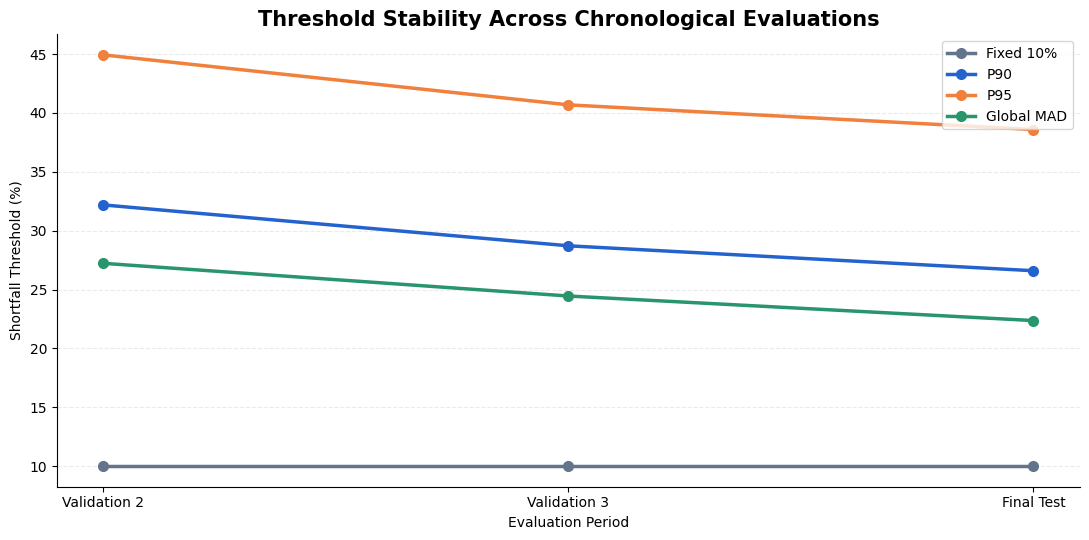


Historical stability evaluation completed.


In [45]:

# ============================================================
# STAGE 3 — HISTORICAL THRESHOLD STABILITY
# Extra Trees | Time-Ordered Evaluation
# No model retraining required
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

output_dir = "/content/walmart_model_comparison"
os.makedirs(output_dir, exist_ok=True)

# Historical validation predictions generated earlier
cal = calibration.copy()

# Preserve chronological ordering
periods = [
    "Validation 1",
    "Validation 2",
    "Validation 3"
]

# ------------------------------------------------------------
# 1. Define threshold calculation
# ------------------------------------------------------------

def calculate_thresholds(data):

    shortfall = data["Shortfall_Pct"].dropna()
    residuals = data["Residual_Pct"].dropna()

    median_error = residuals.median()

    mad = np.median(
        np.abs(residuals - median_error)
    )

    lower_bound = median_error - 2 * mad

    return {
        "Fixed 10%": 10.0,
        "P90": shortfall.quantile(0.90),
        "P95": shortfall.quantile(0.95),
        "Global MAD": max(0.0, -lower_bound)
    }

# ------------------------------------------------------------
# 2. Evaluate thresholds only on FUTURE periods
# ------------------------------------------------------------

stability_records = []
threshold_records = []

# Validation 1 trains/calibrates for Validation 2.
# Validation 1+2 train/calibrate for Validation 3.

for i in [1, 2]:

    historical_periods = periods[:i]
    evaluation_period = periods[i]

    history = cal[
        cal["Period"].isin(historical_periods)
    ].copy()

    future = cal[
        cal["Period"] == evaluation_period
    ].copy()

    assert len(history) > 0
    assert len(future) > 0

    thresholds = calculate_thresholds(history)

    for method, cutoff in thresholds.items():

        flagged = (
            (future["Shortfall_Pct"] > 0)
            & (future["Shortfall_Pct"] >= cutoff)
        )

        stability_records.append({
            "Evaluation": evaluation_period,
            "Method": method,
            "Threshold_Pct": cutoff,
            "Calibration_N": len(history),
            "Evaluation_N": len(future),
            "Flagged": int(flagged.sum()),
            "Flag_Rate_Pct": 100 * flagged.mean(),
            "Flagged_Dollar_Shortfall":
                future.loc[
                    flagged,
                    "Expected_Sales"
                ].sub(
                    future.loc[flagged, "Weekly_Sales"]
                ).clip(lower=0).sum()
        })

        threshold_records.append({
            "Evaluation": evaluation_period,
            "Method": method,
            "Threshold_Pct": cutoff
        })

# ------------------------------------------------------------
# 3. Evaluate final test with ALL earlier validation data
# ------------------------------------------------------------

final_thresholds = calculate_thresholds(cal)

final_eval = et[
    et["Valid_Baseline"]
    & et["Markdown_Recorded"]
].copy()

for method, cutoff in final_thresholds.items():

    flagged = (
        (final_eval["Shortfall_Pct"] > 0)
        & (final_eval["Shortfall_Pct"] >= cutoff)
    )

    stability_records.append({
        "Evaluation": "Final Test",
        "Method": method,
        "Threshold_Pct": cutoff,
        "Calibration_N": len(cal),
        "Evaluation_N": len(final_eval),
        "Flagged": int(flagged.sum()),
        "Flag_Rate_Pct": 100 * flagged.mean(),
        "Flagged_Dollar_Shortfall":
            final_eval.loc[
                flagged, "Dollar_Shortfall"
            ].sum()
    })

    threshold_records.append({
        "Evaluation": "Final Test",
        "Method": method,
        "Threshold_Pct": cutoff
    })

stability_results = pd.DataFrame(stability_records)
threshold_history = pd.DataFrame(threshold_records)

# ------------------------------------------------------------
# 4. Display threshold values
# ------------------------------------------------------------

print("TABLE 1 — THRESHOLDS LEARNED FROM EARLIER PERIODS")

display(
    threshold_history.pivot(
        index="Evaluation",
        columns="Method",
        values="Threshold_Pct"
    ).reindex(
        ["Validation 2", "Validation 3", "Final Test"]
    ).round(2)
)

# ------------------------------------------------------------
# 5. Display future flag rates
# ------------------------------------------------------------

print("\nTABLE 2 — FLAG RATES ON UNSEEN PERIODS")

rate_pivot = stability_results.pivot(
    index="Evaluation",
    columns="Method",
    values="Flag_Rate_Pct"
).reindex(
    ["Validation 2", "Validation 3", "Final Test"]
)

display(rate_pivot.round(2))

# ------------------------------------------------------------
# 6. Plot threshold stability
# ------------------------------------------------------------

plot_data = threshold_history.pivot(
    index="Evaluation",
    columns="Method",
    values="Threshold_Pct"
).reindex(
    ["Validation 2", "Validation 3", "Final Test"]
)

fig, ax = plt.subplots(figsize=(11, 5.5))

colors = {
    "Fixed 10%": "#64748B",
    "P90": "#2463CE",
    "P95": "#F0803C",
    "Global MAD": "#29956D"
}

for method in colors:

    ax.plot(
        plot_data.index,
        plot_data[method],
        marker="o",
        linewidth=2.5,
        markersize=7,
        label=method,
        color=colors[method]
    )

ax.set_title(
    "Threshold Stability Across Chronological Evaluations",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Shortfall Threshold (%)")
ax.set_xlabel("Evaluation Period")

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend()

plt.tight_layout()

plt.savefig(
    f"{output_dir}/threshold_stability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 7. Save detailed results
# ------------------------------------------------------------

stability_results.to_csv(
    f"{output_dir}/threshold_stability_results.csv",
    index=False
)

threshold_history.to_csv(
    f"{output_dir}/threshold_history.csv",
    index=False
)

print("\nHistorical stability evaluation completed.")


### Historical Threshold Stability — Findings

Historical thresholds were calibrated using earlier Extra Trees validation residuals and evaluated on subsequent, unseen periods.

Global MAD thresholds decreased from 27.23% to 24.45% and then 22.36% as additional historical observations became available. Despite this change, the proportion of eligible observations flagged remained relatively consistent at 8.55%, 8.25%, and 10.29%.

Compared with the fixed 10% rule, which flagged 25.24%–31.16% of observations, historical MAD produced a smaller and more consistent investigation workload.

P90 and P95 also showed relatively stable flag rates, with fewer alerts than MAD. Therefore, the stability results alone do not establish a single best method.

Global MAD will remain a provisional detection candidate while the next stage evaluates modeled dollar impact, recurring exceptions, and investigation priorities. Business prioritization will be evaluated separately from anomaly detection.

In [46]:

# ============================================================
# STAGE 4 — BUSINESS-IMPACT PRIORITIZATION
# Extra Trees | Final Test
# Detection and Prioritization Kept Separate
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# 1. Use existing final-test threshold results
# ------------------------------------------------------------

priority_source = test.copy()

# The existing 'test' DataFrame contains:
# Flag_Fixed10, Flag_P90, Flag_P95,
# Flag_GlobalMAD, Flag_TypeMAD

required_columns = [
    "Store", "Dept", "Date", "Type",
    "Actual_Sales", "Expected_Sales",
    "Dollar_Shortfall", "Shortfall_Pct",
    "Flag_Fixed10", "Flag_P90", "Flag_P95",
    "Flag_GlobalMAD", "Flag_TypeMAD"
]

assert all(
    col in priority_source.columns
    for col in required_columns
), "Run the dynamic threshold comparison cell first."

priority_source["Date"] = pd.to_datetime(
    priority_source["Date"]
)

# ------------------------------------------------------------
# 2. Count recurrence across the final-test period
# ------------------------------------------------------------

# Calculate recurrence independently for each detection rule.
# One flag = one department-week exception.

methods = {
    "Fixed 10%": "Flag_Fixed10",
    "P90": "Flag_P90",
    "P95": "Flag_P95",
    "Global MAD": "Flag_GlobalMAD",
    "Type MAD": "Flag_TypeMAD"
}

# ------------------------------------------------------------
# 3. Compare business impact by detection method
# ------------------------------------------------------------

impact_records = []

for method, flag_col in methods.items():

    detected = priority_source[
        priority_source[flag_col]
    ].copy()

    recurring = (
        detected.groupby(["Store", "Dept"])
        .size()
    )

    impact_records.append({
        "Method": method,
        "Flagged_Observations": len(detected),
        "Affected_Store_Departments": len(recurring),
        "Recurring_Store_Departments":
            int((recurring >= 2).sum()),
        "Total_Dollar_Shortfall":
            detected["Dollar_Shortfall"].sum(),
        "Median_Dollar_Shortfall":
            detected["Dollar_Shortfall"].median(),
        "Flags_Over_1000":
            int((detected["Dollar_Shortfall"] >= 1000).sum()),
        "Flags_Over_5000":
            int((detected["Dollar_Shortfall"] >= 5000).sum())
    })

impact_comparison = pd.DataFrame(impact_records)

print("TABLE 1 — BUSINESS IMPACT BY DETECTION METHOD")

display(impact_comparison.round(2))

# ------------------------------------------------------------
# 4. Prioritize cases FLAGGED by provisional Global MAD
# ------------------------------------------------------------

priority_cases = priority_source[
    priority_source["Flag_GlobalMAD"]
].copy()

# Number of flagged weeks per Store-Department
recurrence = (
    priority_cases.groupby(["Store", "Dept"])
    .agg(
        Flagged_Weeks=("Date", "nunique"),
        Total_Flagged_Shortfall=(
            "Dollar_Shortfall", "sum"
        ),
        Largest_Weekly_Shortfall=(
            "Dollar_Shortfall", "max"
        ),
        First_Flag=("Date", "min"),
        Last_Flag=("Date", "max")
    )
    .reset_index()
)

# Add recurrence information to each detected case
priority_cases = priority_cases.merge(
    recurrence[
        ["Store", "Dept", "Flagged_Weeks"]
    ],
    on=["Store", "Dept"],
    how="left",
    validate="many_to_one"
)

# Prioritize larger financial gaps first.
# Recurrence is a secondary ranking factor.
priority_cases = (
    priority_cases.sort_values(
        [
            "Dollar_Shortfall",
            "Flagged_Weeks",
            "Shortfall_Pct"
        ],
        ascending=[False, False, False]
    )
    .reset_index(drop=True)
)

priority_cases.insert(
    0, "Investigation_Rank",
    np.arange(1, len(priority_cases) + 1)
)

print("\nTABLE 2 — TOP 20 PRIORITY INVESTIGATIONS (GLOBAL MAD)")

display(
    priority_cases[
        [
            "Investigation_Rank",
            "Store", "Dept", "Date", "Type",
            "Expected_Sales", "Actual_Sales",
            "Dollar_Shortfall", "Shortfall_Pct",
            "Flagged_Weeks"
        ]
    ].head(20).round(2)
)

# ------------------------------------------------------------
# 5. Identify departments with recurring exceptions
# ------------------------------------------------------------

recurring_departments = (
    recurrence.sort_values(
        [
            "Total_Flagged_Shortfall",
            "Flagged_Weeks"
        ],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

recurring_departments = recurring_departments[
    recurring_departments["Flagged_Weeks"] >= 2
].copy()

print("\nTABLE 3 — RECURRING DEPARTMENT EXCEPTIONS")

display(
    recurring_departments[
        [
            "Store", "Dept",
            "Flagged_Weeks",
            "Total_Flagged_Shortfall",
            "Largest_Weekly_Shortfall",
            "First_Flag", "Last_Flag"
        ]
    ].head(20).round(2)
)

# ------------------------------------------------------------
# 6. Store 7, Department 72 investigation
# ------------------------------------------------------------

store7_case = priority_source[
    (priority_source["Store"] == 7)
    & (priority_source["Dept"] == 72)
].copy()

# Include every week flagged by at least one method
flag_cols = list(methods.values())

store7_case = store7_case[
    store7_case[flag_cols].any(axis=1)
].sort_values("Date")

print("\nTABLE 4 — STORE 7, DEPARTMENT 72")

display(
    store7_case[
        [
            "Date", "Actual_Sales", "Expected_Sales",
            "Dollar_Shortfall", "Shortfall_Pct",
            "Flag_Fixed10", "Flag_P90",
            "Flag_P95", "Flag_GlobalMAD",
            "Flag_TypeMAD"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 7. Export investigation results
# ------------------------------------------------------------

impact_comparison.to_csv(
    f"{output_dir}/business_impact_comparison.csv",
    index=False
)

priority_cases.to_csv(
    f"{output_dir}/global_mad_priority_cases.csv",
    index=False
)

recurring_departments.to_csv(
    f"{output_dir}/recurring_department_exceptions.csv",
    index=False
)

store7_case.to_csv(
    f"{output_dir}/store7_dept72_threshold_comparison.csv",
    index=False
)

print("\nBusiness-impact prioritization completed.")


TABLE 1 — BUSINESS IMPACT BY DETECTION METHOD


,Method,Flagged_Observations,Affected_Store_Departments,Recurring_Store_Departments,Total_Dollar_Shortfall,Median_Dollar_Shortfall,Flags_Over_1000,Flags_Over_5000
0,Fixed 10%,11207,2527,2197,17837181.38,719.70,4622,769
1,P90,3360,1145,756,4598878.94,391.14,1007,203
2,P95,1726,678,391,2375746.67,213.33,444,104
3,Global MAD,4365,1413,981,6216159.38,461.44,1414,271
4,Type MAD,4381,1416,972,6297746.30,473.90,1438,279



TABLE 2 — TOP 20 PRIORITY INVESTIGATIONS (GLOBAL MAD)


,Investigation_Rank,Store,Dept,Date,Type,Expected_Sales,Actual_Sales,Dollar_Shortfall,Shortfall_Pct,Flagged_Weeks
0,1,39,3,2012-09-07,A,76608.93,27998.09,48610.84,63.45,2
1,2,13,3,2012-09-14,A,74704.19,37384.66,37319.53,49.96,3
2,3,27,3,2012-09-14,A,59063.46,24075.61,34987.85,59.24,2
3,4,32,3,2012-08-31,A,54934.03,22061.67,32872.36,59.84,1
4,5,41,3,2012-08-31,A,52181.15,23534.79,28646.36,54.90,2
5,6,14,3,2012-09-14,A,59768.65,31321.66,28446.99,47.60,2
6,7,16,9,2012-09-28,B,51531.59,23504.66,28026.93,54.39,2
7,8,2,3,2012-09-07,A,51281.07,23422.00,27859.07,54.33,2
8,9,11,3,2012-09-07,A,46230.74,18754.06,27476.68,59.43,1
9,10,23,3,2012-09-07,B,54867.55,27449.09,27418.46,49.97,1



TABLE 3 — RECURRING DEPARTMENT EXCEPTIONS


,Store,Dept,Flagged_Weeks,Total_Flagged_Shortfall,Largest_Weekly_Shortfall,First_Flag,Last_Flag
0,39,3,2,60940.96,48610.84,2012-09-07,2012-09-14
1,13,3,3,59371.88,37319.53,2012-09-14,2012-09-28
2,10,3,3,54165.30,22498.40,2012-08-17,2012-08-31
3,16,9,2,50069.57,28026.93,2012-09-28,2012-10-26
4,27,3,2,45701.65,34987.85,2012-09-14,2012-09-21
5,14,3,2,45255.07,28446.99,2012-09-14,2012-09-21
6,4,3,3,41765.34,18135.77,2012-08-24,2012-09-07
7,34,3,3,37107.81,26665.85,2012-08-24,2012-09-07
8,7,9,3,36658.33,15166.74,2012-09-28,2012-10-26
9,23,72,2,36310.76,20475.70,2012-09-07,2012-10-26



TABLE 4 — STORE 7, DEPARTMENT 72


,Date,Actual_Sales,Expected_Sales,Dollar_Shortfall,Shortfall_Pct,Flag_Fixed10,Flag_P90,Flag_P95,Flag_GlobalMAD,Flag_TypeMAD
6676,2012-08-17,40291.02,44886.99,4595.97,10.24,True,False,False,False,False
6677,2012-08-24,33957.54,43905.59,9948.05,22.66,True,False,False,True,False
6684,2012-10-12,35449.75,42603.46,7153.71,16.79,True,False,False,False,False
6685,2012-10-19,31729.10,38809.28,7080.18,18.24,True,False,False,False,False



Business-impact prioritization completed.


### Business-Impact Prioritization — Key Findings

The evaluation of five anomaly detection methods demonstrates a clear trade-off between detection sensitivity and investigation workload.

**First, Global MAD substantially reduced the number of flagged observations**, from 11,207 under the fixed 10% rule to 4,365, a reduction of approximately 61%. However, the reduction in alerts also excluded some observations with substantial modeled dollar shortfalls.

**Second, high-priority exceptions were concentrated in Department 3.** Fourteen of the top 20 ranked observations involved Department 3 across multiple stores, particularly during late August and September 2012. This pattern warrants additional investigation to distinguish possible business events from systematic forecasting errors.

**Third, recurring exceptions provided additional investigation context.** Several store-department combinations experienced multiple flagged weeks with substantial cumulative modeled shortfalls. For example, Store 39, Department 3 accumulated approximately $60,941 across two flagged weeks.

**Fourth, the Store 7, Department 72 case study demonstrated sensitivity to threshold selection.** The fixed 10% rule identified four exceptions, whereas Global MAD identified only the August 24 observation, which had a modeled shortfall of approximately $9,948 (22.66%).

**Overall, the findings support Global MAD as a provisional historical anomaly-screening approach**, while highlighting the importance of keeping business-impact prioritization separate from detection. Dollar shortfall, recurrence, and cross-store patterns can help identify cases for further investigation.

These results do not establish that the flagged observations represent confirmed markdown failures or recoverable financial losses.

Department 3 concentration

In [47]:

# ============================================================
# DEPARTMENT 3 — FORECAST ERROR DIAGNOSTIC
# Final Test: July 20 – October 26, 2012
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Use valid Extra Trees final-test predictions
diagnostic = et[
    et["Valid_Baseline"]
].copy()

diagnostic["Date"] = pd.to_datetime(
    diagnostic["Date"]
)

# 2. Calculate SIGNED forecast error
# Negative means Extra Trees OVERPREDICTED sales
diagnostic["Signed_Error_Pct"] = (
    100 * (
        diagnostic["Actual_Sales"]
        - diagnostic["Expected_Sales"]
    ) / diagnostic["Expected_Sales"]
)

diagnostic["Signed_Error_Dollars"] = (
    diagnostic["Actual_Sales"]
    - diagnostic["Expected_Sales"]
)

# 3. Compare Department 3 with all other departments
diagnostic["Group"] = np.where(
    diagnostic["Dept"] == 3,
    "Department 3",
    "Other Departments"
)

comparison = (
    diagnostic.groupby("Group")
    .agg(
        Observations=("Dept", "size"),
        Stores=("Store", "nunique"),
        Median_Error_Pct=("Signed_Error_Pct", "median"),
        Mean_Error_Pct=("Signed_Error_Pct", "mean"),
        Total_Signed_Error=("Signed_Error_Dollars", "sum"),
        Overpredicted_Rate_Pct=(
            "Signed_Error_Dollars",
            lambda x: 100 * (x < 0).mean()
        )
    )
    .reset_index()
)

print("TABLE 1 — DEPARTMENT 3 VS OTHER DEPARTMENTS")
display(comparison.round(2))

# 4. Summarize Department 3 week by week
dept3 = diagnostic[
    diagnostic["Dept"] == 3
].copy()

weekly_diagnostic = (
    dept3.groupby("Date")
    .agg(
        Stores=("Store", "nunique"),
        Actual_Sales=("Actual_Sales", "sum"),
        Expected_Sales=("Expected_Sales", "sum"),
        Median_Error_Pct=("Signed_Error_Pct", "median"),
        Stores_Overpredicted=(
            "Signed_Error_Dollars",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

weekly_diagnostic["Overpredicted_Rate_Pct"] = (
    100 * weekly_diagnostic["Stores_Overpredicted"]
    / weekly_diagnostic["Stores"]
)

weekly_diagnostic["Aggregate_Error_Pct"] = (
    100 * (
        weekly_diagnostic["Actual_Sales"]
        - weekly_diagnostic["Expected_Sales"]
    ) / weekly_diagnostic["Expected_Sales"]
)

print("\nTABLE 2 — DEPARTMENT 3 WEEKLY ERRORS")
display(weekly_diagnostic.round(2))


TABLE 1 — DEPARTMENT 3 VS OTHER DEPARTMENTS


,Group,Observations,Stores,Median_Error_Pct,Mean_Error_Pct,Total_Signed_Error,Overpredicted_Rate_Pct
0,Department 3,675,45,-2.94,-1.62,-14071.08,56.30
1,Other Departments,41725,45,-2.32,-2.11,-7364936.80,58.97



TABLE 2 — DEPARTMENT 3 WEEKLY ERRORS


,Date,Stores,Actual_Sales,Expected_Sales,Median_Error_Pct,Stores_Overpredicted,Overpredicted_Rate_Pct,Aggregate_Error_Pct
0,2012-07-20,45,827938.58,617006.58,30.74,4,8.89,34.19
1,2012-07-27,45,851286.64,852640.01,-3.15,26,57.78,-0.16
2,2012-08-03,45,1104998.65,950672.83,13.43,6,13.33,16.23
3,2012-08-10,45,1286478.13,1208470.09,6.66,17,37.78,6.46
4,2012-08-17,45,1533531.87,1387383.18,5.44,15,33.33,10.53
5,2012-08-24,45,1803173.56,1556401.27,16.67,10,22.22,15.86
6,2012-08-31,45,1645308.80,1619286.32,9.25,15,33.33,1.61
7,2012-09-07,45,1024883.43,1363628.86,-44.89,37,82.22,-24.84
8,2012-09-14,45,562621.87,878713.74,-24.63,44,97.78,-35.97
9,2012-09-21,45,409312.09,530455.84,-16.47,41,91.11,-22.84


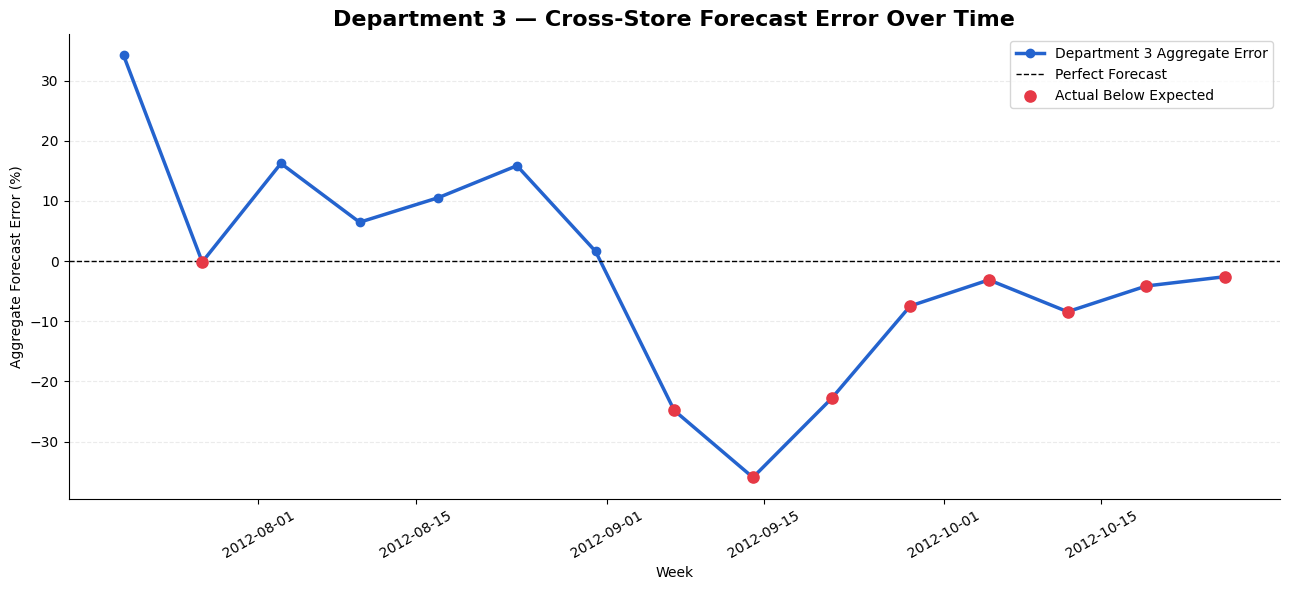

In [48]:

# ============================================================
# DEPARTMENT 3 — CROSS-STORE ERROR VISUALIZATION
# ============================================================

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    weekly_diagnostic["Date"],
    weekly_diagnostic["Aggregate_Error_Pct"],
    color="#2463CE",
    marker="o",
    linewidth=2.5,
    label="Department 3 Aggregate Error"
)

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Perfect Forecast"
)

# Highlight weeks with negative aggregate error
negative_weeks = weekly_diagnostic[
    weekly_diagnostic["Aggregate_Error_Pct"] < 0
]

ax.scatter(
    negative_weeks["Date"],
    negative_weeks["Aggregate_Error_Pct"],
    color="#E63946",
    s=65,
    zorder=5,
    label="Actual Below Expected"
)

ax.set_title(
    "Department 3 — Cross-Store Forecast Error Over Time",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Week")
ax.set_ylabel("Aggregate Forecast Error (%)")

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend()

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [49]:
# Department 3 — Cross-store consistency check

display(
    weekly_diagnostic[
        [
            "Date",
            "Stores",
            "Stores_Overpredicted",
            "Overpredicted_Rate_Pct",
            "Aggregate_Error_Pct"
        ]
    ].sort_values("Date").round(2)
)

,Date,Stores,Stores_Overpredicted,Overpredicted_Rate_Pct,Aggregate_Error_Pct
0,2012-07-20,45,4,8.89,34.19
1,2012-07-27,45,26,57.78,-0.16
2,2012-08-03,45,6,13.33,16.23
3,2012-08-10,45,17,37.78,6.46
4,2012-08-17,45,15,33.33,10.53
5,2012-08-24,45,10,22.22,15.86
6,2012-08-31,45,15,33.33,1.61
7,2012-09-07,45,37,82.22,-24.84
8,2012-09-14,45,44,97.78,-35.97
9,2012-09-21,45,41,91.11,-22.84


DEPARTMENT 3 — HISTORICAL WEEKLY SALES


Year,2010,2011,2012
Week,,,
28,653314.70,544806.51,589837.49
29,743785.11,721942.56,827938.58
30,898057.09,857413.23,851286.64
31,1110118.36,1097011.27,1104998.65
32,1290841.10,1325741.41,1286478.13
33,1614030.53,1700775.01,1533531.87
34,1712142.12,1816910.19,1803173.56
35,1156486.40,1166310.87,1645308.80
36,753846.33,885746.06,1024883.43


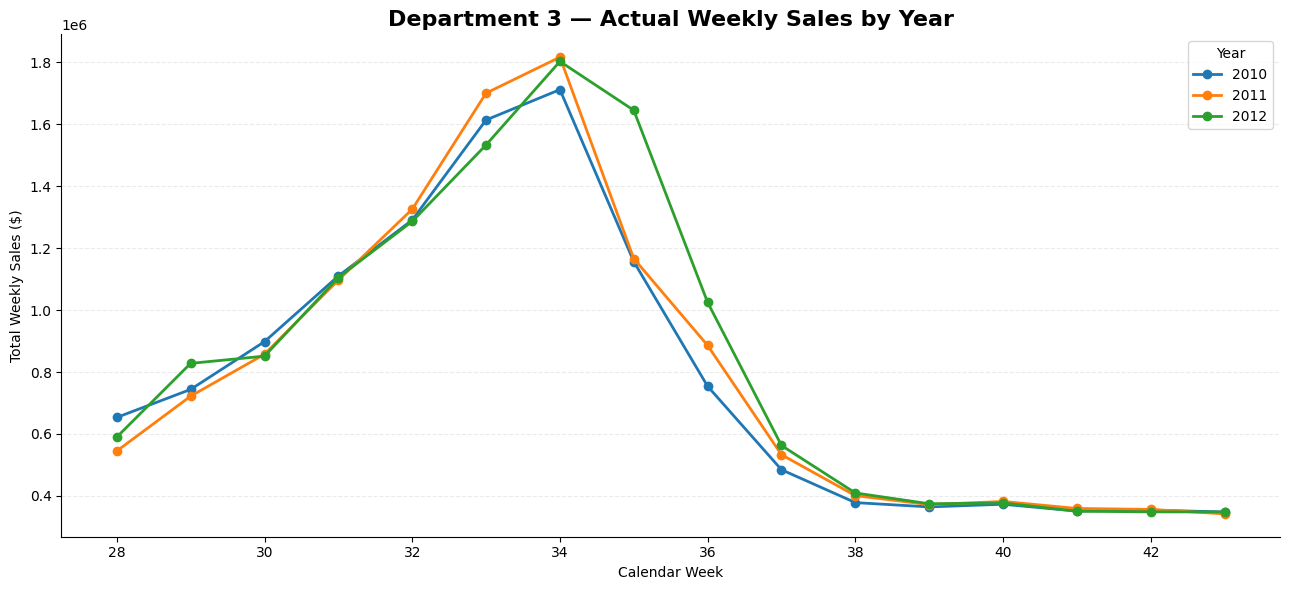

In [50]:

# ============================================================
# DEPARTMENT 3 — HISTORICAL SEASONALITY CHECK
# Compare 2010, 2011, 2012 Actual Weekly Sales
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Use ORIGINAL sales data, not model predictions
seasonal = sales[sales["Dept"] == 3].copy()
seasonal["Date"] = pd.to_datetime(seasonal["Date"])

seasonal["Year"] = seasonal["Date"].dt.year
seasonal["Week"] = seasonal["Date"].dt.isocalendar().week.astype(int)

# Aggregate actual weekly sales across all stores
weekly = (
    seasonal.groupby(["Year", "Week"], as_index=False)
    .agg(
        Total_Actual_Sales=("Weekly_Sales", "sum"),
        Stores=("Store", "nunique")
    )
)

# Focus on July through October
weekly = weekly[
    weekly["Week"].between(28, 43)
].copy()

# Compare the same weeks each year
comparison = weekly.pivot(
    index="Week",
    columns="Year",
    values="Total_Actual_Sales"
)

print("DEPARTMENT 3 — HISTORICAL WEEKLY SALES")
display(comparison.round(2))

# Create chart
fig, ax = plt.subplots(figsize=(13, 6))

for year, group in weekly.groupby("Year"):
    ax.plot(
        group["Week"],
        group["Total_Actual_Sales"],
        marker="o",
        linewidth=2,
        label=str(year)
    )

ax.set_title(
    "Department 3 — Actual Weekly Sales by Year",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Calendar Week")
ax.set_ylabel("Total Weekly Sales ($)")

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(title="Year")

plt.tight_layout()
plt.show()


### Department 3 — Historical Seasonality Findings

A comparison of Department 3's actual weekly sales across 2010, 2011, and 2012 reveals a consistent seasonal pattern. Sales increase through July and August, peak around calendar week 34, and then decline sharply during September before stabilizing in October.

This historical pattern provides important context for the concentration of Global MAD exceptions in Department 3 during September 2012. In particular, Extra Trees overpredicted Department 3 sales in 44 of 45 stores on September 14, suggesting the forecasting model may not have fully captured the rapid seasonal decline.

The findings indicate that some flagged deviations may reflect forecasting limitations associated with seasonal demand transitions rather than unexpected markdown-related issues. However, the historical pattern alone does not establish the cause of the forecasting errors.

These results highlight the value of incorporating seasonality and cross-store context into business investigation before interpreting detected anomalies as operational failures.

**Seasonality & External Factor Investigation**

In [51]:

# ============================================================
# STAGE 5 — SEASONALITY & EXTERNAL FACTOR DIAGNOSTIC
# Top 20 Global MAD Cases + Store 7, Department 72
# No inferred department names or locations
# ============================================================

import os
import numpy as np
import pandas as pd
from IPython.display import display

output_dir = "/content/walmart_model_comparison"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# 1. SELECT HIGH-PRIORITY CASES
# ------------------------------------------------------------

selected = priority_cases.head(20).copy()
selected["Date"] = pd.to_datetime(selected["Date"])

# Also include our Store 7 / Department 72 case study
case72 = priority_cases[
    (priority_cases["Store"] == 7) &
    (priority_cases["Dept"] == 72) &
    (pd.to_datetime(priority_cases["Date"]) ==
     pd.Timestamp("2012-08-24"))
].copy()

selected = pd.concat(
    [selected, case72],
    ignore_index=True
).drop_duplicates(
    ["Store", "Dept", "Date"]
)

# ------------------------------------------------------------
# 2. HISTORICAL SAME-SEASON CONTEXT
# ------------------------------------------------------------

history = sales.copy()
history["Date"] = pd.to_datetime(history["Date"])
history["Year"] = history["Date"].dt.year
history["Week"] = (
    history["Date"].dt.isocalendar().week.astype(int)
)

# Only earlier years — not the current test year
history = history[
    history["Year"].isin([2010, 2011])
].copy()

seasonal_reference = (
    history.groupby(["Store", "Dept", "Week"])
    .agg(
        Historical_Sales_Mean=("Weekly_Sales", "mean"),
        Historical_Weeks=("Weekly_Sales", "size"),
        Historical_Years=("Year", "nunique")
    )
    .reset_index()
)

selected["Week"] = (
    selected["Date"].dt.isocalendar().week.astype(int)
)

selected = selected.merge(
    seasonal_reference,
    on=["Store", "Dept", "Week"],
    how="left",
    validate="many_to_one"
)

# Actual 2012 sales compared with earlier same-week sales
selected["Vs_Historical_Pct"] = np.where(
    selected["Historical_Sales_Mean"] > 0,
    100 * (
        selected["Actual_Sales"] -
        selected["Historical_Sales_Mean"]
    ) / selected["Historical_Sales_Mean"],
    np.nan
)

# ------------------------------------------------------------
# 3. CROSS-STORE FORECAST CONTEXT
# ------------------------------------------------------------

all_predictions = et[
    et["Valid_Baseline"]
].copy()

all_predictions["Date"] = pd.to_datetime(
    all_predictions["Date"]
)

all_predictions["Overpredicted"] = (
    all_predictions["Actual_Sales"] <
    all_predictions["Expected_Sales"]
)

cross_store = (
    all_predictions.groupby(["Dept", "Date"])
    .agg(
        Stores_Compared=("Store", "nunique"),
        Stores_Overpredicted=("Overpredicted", "sum")
    )
    .reset_index()
)

cross_store["Cross_Store_Overprediction_Pct"] = (
    100 *
    cross_store["Stores_Overpredicted"] /
    cross_store["Stores_Compared"]
)

selected = selected.merge(
    cross_store,
    on=["Dept", "Date"],
    how="left",
    validate="many_to_one"
)

# ------------------------------------------------------------
# 4. EXTERNAL FACTORS & MARKDOWN CONTEXT
# ------------------------------------------------------------

external_cols = [
    "Temperature", "Fuel_Price",
    "CPI", "Unemployment"
]

markdown_cols = [
    "MarkDown1", "MarkDown2", "MarkDown3",
    "MarkDown4", "MarkDown5"
]

external = features_data[
    ["Store", "Date"] +
    external_cols +
    markdown_cols
].copy()

external["Date"] = pd.to_datetime(external["Date"])

assert not external.duplicated(
    ["Store", "Date"]
).any(), "Duplicate Store-Date context records found."

external["Markdown_Recorded"] = (
    external[markdown_cols].notna().any(axis=1)
)

selected = selected.drop(
    columns=["Markdown_Recorded"],
    errors="ignore"
)

selected = selected.merge(
    external,
    on=["Store", "Date"],
    how="left",
    validate="many_to_one"
)

# ------------------------------------------------------------
# 5. PREPARE INVESTIGATION OUTPUT
# ------------------------------------------------------------

columns = [
    "Store", "Dept", "Date", "Type",
    "Expected_Sales", "Actual_Sales",
    "Dollar_Shortfall", "Shortfall_Pct",
    "Flagged_Weeks",
    "Historical_Sales_Mean",
    "Historical_Years",
    "Vs_Historical_Pct",
    "Stores_Compared",
    "Stores_Overpredicted",
    "Cross_Store_Overprediction_Pct",
    "Temperature", "Fuel_Price",
    "CPI", "Unemployment",
    "Markdown_Recorded",
    "MarkDown1", "MarkDown2",
    "MarkDown3", "MarkDown4", "MarkDown5"
]

investigation_evidence = selected[
    columns
].copy()

print("INVESTIGATION EVIDENCE — SELECTED CASES")

display(
    investigation_evidence[
        [
            "Store", "Dept", "Date",
            "Dollar_Shortfall",
            "Shortfall_Pct",
            "Flagged_Weeks",
            "Vs_Historical_Pct",
            "Cross_Store_Overprediction_Pct",
            "Markdown_Recorded"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 6. EXPORT FOR AI/RAG HANDOFF
# ------------------------------------------------------------

investigation_evidence.to_csv(
    f"{output_dir}/investigation_evidence.csv",
    index=False
)

print("\nEvidence table saved.")
print("Selected cases:", len(investigation_evidence))


INVESTIGATION EVIDENCE — SELECTED CASES


,Store,Dept,Date,Dollar_Shortfall,Shortfall_Pct,Flagged_Weeks,Vs_Historical_Pct,Cross_Store_Overprediction_Pct,Markdown_Recorded
0,39,3,2012-09-07,48610.84,63.45,2,73.26,82.22,True
1,13,3,2012-09-14,37319.53,49.96,3,68.08,97.78,True
2,27,3,2012-09-14,34987.85,59.24,2,14.40,97.78,True
3,32,3,2012-08-31,32872.36,59.84,1,30.01,33.33,True
4,41,3,2012-08-31,28646.36,54.90,2,39.64,33.33,True
5,14,3,2012-09-14,28446.99,47.60,2,17.10,97.78,True
6,16,9,2012-09-28,28026.93,54.39,2,7.54,62.22,True
7,2,3,2012-09-07,27859.07,54.33,2,50.25,82.22,True
8,11,3,2012-09-07,27476.68,59.43,1,33.82,82.22,True
9,23,3,2012-09-07,27418.46,49.97,1,-2.41,82.22,True



Evidence table saved.
Selected cases: 21


In [52]:

# ============================================================
# STAGE 6 — HISTORICAL EXTERNAL FACTOR COMPARISON
# Top 20 Global MAD Cases + Store 7, Dept 72
# No model retraining
# ============================================================

import os
import numpy as np
import pandas as pd
from IPython.display import display

output_dir = "/content/walmart_model_comparison"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# 1. PREPARE THE 21 INVESTIGATION CASES
# ------------------------------------------------------------

evidence = investigation_evidence.copy()
evidence["Date"] = pd.to_datetime(evidence["Date"])
evidence = evidence.reset_index(drop=True)

evidence["Case_ID"] = np.arange(1, len(evidence) + 1)
evidence["Year"] = evidence["Date"].dt.year
evidence["Week"] = (
    evidence["Date"].dt.isocalendar().week.astype(int)
)

external_cols = [
    "Temperature",
    "Fuel_Price",
    "CPI",
    "Unemployment"
]

markdown_cols = [
    "MarkDown1", "MarkDown2", "MarkDown3",
    "MarkDown4", "MarkDown5"
]

# ------------------------------------------------------------
# 2. PREPARE HISTORICAL STORE-WEEK DATA
# ------------------------------------------------------------

history = features_data[
    ["Store", "Date"] + external_cols + markdown_cols
].copy()

history["Date"] = pd.to_datetime(history["Date"])

assert not history.duplicated(
    ["Store", "Date"]
).any(), "Duplicate historical store-week records."

history["Year"] = history["Date"].dt.year
history["Week"] = (
    history["Date"].dt.isocalendar().week.astype(int)
)

# Match historical observations from the SAME store.
# Reference window: same calendar week +/- 2 weeks.
#
# Example: Week 36 in 2012 is compared with
# Weeks 34–38 in 2010 and 2011.
#
# Only PRIOR years may enter the reference.

matches = evidence[
    ["Case_ID", "Store", "Year", "Week"]
].merge(
    history,
    on="Store",
    how="left",
    suffixes=("_Case", "_Hist")
)

# Circular week distance handles year boundaries.
week_distance = (
    matches["Week_Case"] - matches["Week_Hist"]
).abs()

week_distance = np.minimum(
    week_distance,
    52 - np.minimum(week_distance, 52)
)

matches = matches[
    (matches["Year_Hist"] < matches["Year_Case"])
    & (week_distance <= 2)
].copy()

# ------------------------------------------------------------
# 3. CALCULATE HISTORICAL REFERENCE STATISTICS
# ------------------------------------------------------------

MIN_HISTORY = 6

all_factors = external_cols + markdown_cols

records = []

for case_id, group in matches.groupby("Case_ID"):

    row = {"Case_ID": case_id}

    for factor in all_factors:

        values = pd.to_numeric(
            group[factor], errors="coerce"
        ).dropna()

        row[f"{factor}_Hist_N"] = len(values)

        if len(values):
            row[f"{factor}_Hist_Median"] = values.median()
        else:
            row[f"{factor}_Hist_Median"] = np.nan

        # Only estimate reference percentiles when enough
        # recorded historical observations exist.
        if len(values) >= MIN_HISTORY:
            row[f"{factor}_Hist_P10"] = values.quantile(0.10)
            row[f"{factor}_Hist_P90"] = values.quantile(0.90)
        else:
            row[f"{factor}_Hist_P10"] = np.nan
            row[f"{factor}_Hist_P90"] = np.nan

    records.append(row)

historical_stats = pd.DataFrame(
    records,
    columns=["Case_ID"] + [
        f"{factor}_{suffix}"
        for factor in all_factors
        for suffix in [
            "Hist_N", "Hist_Median",
            "Hist_P10", "Hist_P90"
        ]
    ]
)

evidence = evidence.merge(
    historical_stats,
    on="Case_ID",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 4. COMPARE CURRENT VALUES WITH HISTORICAL VALUES
# ------------------------------------------------------------

for factor in all_factors:

    current = pd.to_numeric(
        evidence[factor], errors="coerce"
    )

    median = evidence[f"{factor}_Hist_Median"]
    low = evidence[f"{factor}_Hist_P10"]
    high = evidence[f"{factor}_Hist_P90"]
    n = evidence[f"{factor}_Hist_N"].fillna(0)

    # Absolute difference:
    # Temperature -> degrees F
    # Fuel Price -> dollars
    # CPI -> index points
    # Unemployment -> percentage points
    # Markdown -> original dataset units
    evidence[f"{factor}_Difference"] = (
        current - median
    )

    # Relative percentage change against historical median.
    # Avoid dividing by zero or near-zero baselines.
    evidence[f"{factor}_Change_Pct"] = np.where(
        median.abs() > 1e-8,
        100 * (current - median) / median.abs(),
        np.nan
    )

    evidence[f"{factor}_Historical_Status"] = np.select(
        [
            current.isna(),
            n < MIN_HISTORY,
            current < low,
            current > high
        ],
        [
            "Current Missing",
            "Insufficient History",
            "Below Historical P10",
            "Above Historical P90"
        ],
        default="Within Historical P10-P90"
    )

# ------------------------------------------------------------
# 5. DISPLAY A COMPACT BUSINESS INVESTIGATION TABLE
# ------------------------------------------------------------

summary_cols = [
    "Store", "Dept", "Date",
    "Dollar_Shortfall", "Shortfall_Pct",
    "Temperature", "Temperature_Hist_Median",
    "Temperature_Difference",
    "Temperature_Historical_Status",
    "Fuel_Price", "Fuel_Price_Hist_Median",
    "Fuel_Price_Historical_Status",
    "CPI_Historical_Status",
    "Unemployment_Historical_Status"
]

print("STAGE 6 — EXTERNAL FACTOR COMPARISON")

display(
    evidence[summary_cols].round(2)
)

# ------------------------------------------------------------
# 6. SAVE FULL EVIDENCE TABLE
# ------------------------------------------------------------

evidence.to_csv(
    f"{output_dir}/investigation_evidence_with_external_comparison.csv",
    index=False
)

print("\nCompleted:", len(evidence), "cases")
print("Historical external-factor evidence saved.")


STAGE 6 — EXTERNAL FACTOR COMPARISON


,Store,Dept,Date,Dollar_Shortfall,Shortfall_Pct,Temperature,Temperature_Hist_Median,Temperature_Difference,Temperature_Historical_Status,Fuel_Price,Fuel_Price_Hist_Median,Fuel_Price_Historical_Status,CPI_Historical_Status,Unemployment_Historical_Status
0,39,3,2012-09-07,48610.84,63.45,83.71,81.98,1.73,Within Historical P10-P90,3.73,3.05,Above Historical P90,Above Historical P90,Below Historical P10
1,13,3,2012-09-14,37319.53,49.96,68.55,67.88,0.67,Within Historical P10-P90,3.75,3.23,Above Historical P90,Above Historical P90,Below Historical P10
2,27,3,2012-09-14,34987.85,59.24,68.72,70.28,-1.56,Within Historical P10-P90,4.09,3.36,Above Historical P90,Above Historical P90,Above Historical P90
3,32,3,2012-08-31,32872.36,59.84,76.12,70.83,5.29,Above Historical P90,3.56,3.14,Within Historical P10-P90,Above Historical P90,Below Historical P10
4,41,3,2012-08-31,28646.36,54.90,71.56,65.16,6.40,Above Historical P90,3.56,3.14,Within Historical P10-P90,Above Historical P90,Below Historical P10
5,14,3,2012-09-14,28446.99,47.60,67.87,70.60,-2.73,Within Historical P10-P90,3.95,3.18,Above Historical P90,Above Historical P90,Within Historical P10-P90
6,16,9,2012-09-28,28026.93,54.39,51.40,53.98,-2.59,Within Historical P10-P90,3.79,3.15,Above Historical P90,Above Historical P90,Below Historical P10
7,2,3,2012-09-07,27859.07,54.33,87.65,81.81,5.84,Within Historical P10-P90,3.73,3.05,Above Historical P90,Above Historical P90,Below Historical P10
8,11,3,2012-09-07,27476.68,59.43,85.17,84.92,0.25,Within Historical P10-P90,3.73,3.05,Above Historical P90,Above Historical P90,Below Historical P10
9,23,3,2012-09-07,27418.46,49.97,66.74,63.23,3.51,Within Historical P10-P90,3.92,3.26,Above Historical P90,Above Historical P90,Below Historical P10



Completed: 21 cases
Historical external-factor evidence saved.


In [53]:

# ============================================================
# STAGE 6 — SUMMARIZE EXTERNAL FACTOR SIGNALS
# ============================================================

factor_labels = {
    "Temperature": "Temperature",
    "Fuel_Price": "Fuel Price",
    "CPI": "CPI",
    "Unemployment": "Unemployment",
    "MarkDown1": "MarkDown1",
    "MarkDown2": "MarkDown2",
    "MarkDown3": "MarkDown3",
    "MarkDown4": "MarkDown4",
    "MarkDown5": "MarkDown5"
}

rows = []

for _, case in evidence.iterrows():

    for factor, label in factor_labels.items():

        status = case[f"{factor}_Historical_Status"]

        rows.append({
            "Store": case["Store"],
            "Dept": case["Dept"],
            "Date": case["Date"],
            "Factor": label,
            "Current_Value": case[factor],
            "Historical_Median":
                case[f"{factor}_Hist_Median"],
            "Historical_N":
                case[f"{factor}_Hist_N"],
            "Difference":
                case[f"{factor}_Difference"],
            "Historical_Status": status,
            "Dollar_Shortfall":
                case["Dollar_Shortfall"]
        })

factor_detail = pd.DataFrame(rows)

# Highlight only factors outside their historical reference
unusual_factors = factor_detail[
    factor_detail["Historical_Status"].isin([
        "Below Historical P10",
        "Above Historical P90"
    ])
].copy()

print("POTENTIALLY UNUSUAL EXTERNAL FACTORS")

display(
    unusual_factors.sort_values(
        ["Dollar_Shortfall", "Store", "Factor"],
        ascending=[False, True, True]
    ).round(2)
)

print("\nUNUSUAL FACTOR COUNTS")

display(
    unusual_factors.groupby(
        ["Factor", "Historical_Status"]
    ).size().reset_index(name="Cases")
)

# Inspect the original individual case study
print("\nSTORE 7 — DEPARTMENT 72 — AUG 24")

display(
    factor_detail[
        (factor_detail["Store"] == 7) &
        (factor_detail["Dept"] == 72) &
        (factor_detail["Date"] == pd.Timestamp("2012-08-24"))
    ].round(2)
)

# Export
factor_detail.to_csv(
    f"{output_dir}/external_factor_detailed_comparison.csv",
    index=False
)

unusual_factors.to_csv(
    f"{output_dir}/unusual_external_factor_signals.csv",
    index=False
)

print("\nExternal factor diagnostic completed.")


POTENTIALLY UNUSUAL EXTERNAL FACTORS


,Store,Dept,Date,Factor,Current_Value,Historical_Median,Historical_N,Difference,Historical_Status,Dollar_Shortfall
2,39,3,2012-09-07,CPI,221.12,212.43,10,8.69,Above Historical P90,48610.84
1,39,3,2012-09-07,Fuel Price,3.73,3.05,10,0.68,Above Historical P90,48610.84
3,39,3,2012-09-07,Unemployment,6.62,8.27,10,-1.65,Below Historical P10,48610.84
11,13,3,2012-09-14,CPI,130.98,127.78,10,3.20,Above Historical P90,37319.53
10,13,3,2012-09-14,Fuel Price,3.75,3.23,10,0.52,Above Historical P90,37319.53
...,...,...,...,...,...,...,...,...,...,...
172,12,3,2012-09-07,Fuel Price,4.12,3.43,10,0.69,Above Historical P90,21442.19
174,12,3,2012-09-07,Unemployment,10.93,13.84,10,-2.92,Below Historical P10,21442.19
182,7,72,2012-08-24,CPI,198.10,192.25,10,5.85,Above Historical P90,9948.05
181,7,72,2012-08-24,Fuel Price,3.56,3.13,10,0.43,Above Historical P90,9948.05



UNUSUAL FACTOR COUNTS


,Factor,Historical_Status,Cases
0,CPI,Above Historical P90,21
1,Fuel Price,Above Historical P90,19
2,Temperature,Above Historical P90,2
3,Unemployment,Above Historical P90,1
4,Unemployment,Below Historical P10,18



STORE 7 — DEPARTMENT 72 — AUG 24


,Store,Dept,Date,Factor,Current_Value,Historical_Median,Historical_N,Difference,Historical_Status,Dollar_Shortfall
180,7,72,2012-08-24,Temperature,59.27,55.31,10,3.96,Within Historical P10-P90,9948.05
181,7,72,2012-08-24,Fuel Price,3.56,3.13,10,0.43,Above Historical P90,9948.05
182,7,72,2012-08-24,CPI,198.10,192.25,10,5.85,Above Historical P90,9948.05
183,7,72,2012-08-24,Unemployment,7.87,8.82,10,-0.95,Below Historical P10,9948.05
184,7,72,2012-08-24,MarkDown1,2534.52,NaN,0,NaN,Insufficient History,9948.05
185,7,72,2012-08-24,MarkDown2,19.60,NaN,0,NaN,Insufficient History,9948.05
186,7,72,2012-08-24,MarkDown3,1.86,NaN,0,NaN,Insufficient History,9948.05
187,7,72,2012-08-24,MarkDown4,1627.26,NaN,0,NaN,Insufficient History,9948.05
188,7,72,2012-08-24,MarkDown5,3915.85,NaN,0,NaN,Insufficient History,9948.05



External factor diagnostic completed.


**Historical External Factor Comparison: Key Findings**

The historical external-factor analysis examined 21 selected Global MAD investigation cases using comparable seasonal weeks from previous years.

**Economic factors:** CPI exceeded the historical 90th percentile in all 21 cases, while fuel prices exceeded this threshold in 19 cases. Unemployment was below the historical 10th percentile in 18 cases. These widespread differences may reflect broader economic trends rather than conditions uniquely associated with individual sales exceptions.

**Temperature:** Only two cases showed temperatures above the historical 90th percentile, suggesting that unusually high temperatures were not a widespread characteristic of the selected exceptions.

**Store 7, Department 72:** On August 24, 2012, the department experienced a modeled sales shortfall of $9,948 (22.66%). Temperature remained within its historical seasonal range, while fuel price and CPI exceeded historical upper reference levels and unemployment was below its lower reference level.

**Markdown data limitations:** All five markdown variables contained recorded values for the Store 7 case. However, no comparable historical markdown observations were available in the selected previous-year reference window. Consequently, historical markdown deviations could not be evaluated.

**Overall conclusion:** External-factor comparisons provide supporting investigation context but do not establish that economic conditions, temperature, or markdown activity caused the flagged sales shortfalls. Additional recent-trend comparisons and contextual evidence are needed before drawing operational conclusions.

In [54]:

# ============================================================
# STAGE 7 — SHORT-TERM ECONOMIC & MARKDOWN COMPARISON
# Top 20 Global MAD cases + Store 7, Dept 72
# Prior 4 and 8 calendar weeks only
# ============================================================

import os
import numpy as np
import pandas as pd
from IPython.display import display

output_dir = "/content/walmart_model_comparison"
os.makedirs(output_dir, exist_ok=True)

# 1. Investigation cases from Stage 5
cases = investigation_evidence.copy()
cases["Date"] = pd.to_datetime(cases["Date"])
cases = cases.reset_index(drop=True)
cases["Case_ID"] = np.arange(1, len(cases) + 1)

economic_cols = [
    "Fuel_Price", "CPI", "Unemployment"
]

markdown_cols = [
    "MarkDown1", "MarkDown2", "MarkDown3",
    "MarkDown4", "MarkDown5"
]

factor_cols = ["Temperature"] + economic_cols + markdown_cols

# 2. Original store-week data
context = features_data[
    ["Store", "Date"] + factor_cols
].copy()

context["Date"] = pd.to_datetime(context["Date"])

assert not context.duplicated(
    ["Store", "Date"]
).any(), "Duplicate Store-Date records detected."

# 3. Match each case with its earlier store-weeks
history = cases[
    ["Case_ID", "Store", "Date"]
].merge(
    context,
    on="Store",
    how="left",
    suffixes=("_Case", "_History")
)

history["Days_Before"] = (
    history["Date_Case"] -
    history["Date_History"]
).dt.days

# Strictly PREVIOUS weeks: exclude current case date
history = history[
    history["Days_Before"].between(1, 56)
    & (history["Days_Before"] % 7 == 0)
].copy()

# 4. Calculate 4-week and 8-week baselines
records = []

for case_id in cases["Case_ID"]:

    group = history[
        history["Case_ID"] == case_id
    ]

    result = {"Case_ID": case_id}

    for window in [4, 8]:

        prior = group[
            group["Days_Before"] <= window * 7
        ].copy()

        for factor in factor_cols:

            values = pd.to_numeric(
                prior[factor], errors="coerce"
            ).dropna()

            # Require sufficient recent recorded values.
            # Economic fields generally have full coverage.
            minimum_n = max(2, window // 2)

            result[f"{factor}_Prev{window}_N"] = len(values)

            result[f"{factor}_Prev{window}_Median"] = (
                values.median()
                if len(values) >= minimum_n
                else np.nan
            )

    records.append(result)

recent_stats = pd.DataFrame(records)

cases_recent = cases.merge(
    recent_stats,
    on="Case_ID",
    how="left",
    validate="one_to_one"
)

# 5. Calculate differences from the recent baselines
for window in [4, 8]:

    for factor in factor_cols:

        current = pd.to_numeric(
            cases_recent[factor], errors="coerce"
        )

        historical = cases_recent[
            f"{factor}_Prev{window}_Median"
        ]

        cases_recent[f"{factor}_Prev{window}_Difference"] = (
            current - historical
        )

        cases_recent[f"{factor}_Prev{window}_Change_Pct"] = np.where(
            historical.abs() > 1e-8,
            100 * (current - historical)
            / historical.abs(),
            np.nan
        )

# 6. Summary table: recent 4-week comparison
summary_cols = [
    "Store", "Dept", "Date",
    "Dollar_Shortfall", "Shortfall_Pct",
    "Fuel_Price_Prev4_Difference",
    "CPI_Prev4_Difference",
    "Unemployment_Prev4_Difference",
    "MarkDown1_Prev4_Change_Pct",
    "MarkDown2_Prev4_Change_Pct",
    "MarkDown3_Prev4_Change_Pct",
    "MarkDown4_Prev4_Change_Pct",
    "MarkDown5_Prev4_Change_Pct"
]

print("STAGE 7 — RECENT 4-WEEK FACTOR COMPARISON")

display(cases_recent[summary_cols].round(2))

# 7. Save complete results
cases_recent.to_csv(
    f"{output_dir}/investigation_recent_factor_comparison.csv",
    index=False
)

print("\nRecent factor comparisons completed.")
print("Cases analyzed:", len(cases_recent))


STAGE 7 — RECENT 4-WEEK FACTOR COMPARISON


,Store,Dept,Date,Dollar_Shortfall,Shortfall_Pct,Fuel_Price_Prev4_Difference,CPI_Prev4_Difference,Unemployment_Prev4_Difference,MarkDown1_Prev4_Change_Pct,MarkDown2_Prev4_Change_Pct,MarkDown3_Prev4_Change_Pct,MarkDown4_Prev4_Change_Pct,MarkDown5_Prev4_Change_Pct
0,39,3,2012-09-07,48610.84,63.45,0.13,0.33,0.0,121.72,-68.82,500.88,-59.42,-13.76
1,13,3,2012-09-14,37319.53,49.96,0.15,0.12,0.0,-1.48,NaN,-64.41,-79.63,94.61
2,27,3,2012-09-14,34987.85,59.24,0.08,0.24,0.0,44.19,-69.27,-90.63,-37.28,-39.08
3,32,3,2012-08-31,32872.36,59.84,0.02,0.01,0.0,213.16,34.85,-16.60,-0.64,-30.01
4,41,3,2012-08-31,28646.36,54.90,0.02,0.01,0.0,98.08,-75.12,131.06,6.31,101.27
5,14,3,2012-09-14,28446.99,47.60,0.10,0.30,0.0,70.59,NaN,-63.69,-82.27,-60.51
6,16,9,2012-09-28,28026.93,54.39,0.16,0.48,0.0,-53.87,194.67,NaN,-32.05,-68.57
7,2,3,2012-09-07,27859.07,54.33,0.13,0.33,0.0,106.39,-15.58,408.93,-30.79,-34.68
8,11,3,2012-09-07,27476.68,59.43,0.13,0.34,0.0,24.26,-54.94,67.66,0.51,-36.74
9,23,3,2012-09-07,27418.46,49.97,0.06,0.24,0.0,33.11,8.66,5.31,-74.58,15.28



Recent factor comparisons completed.
Cases analyzed: 21


In [55]:

# ============================================================
# STAGE 7 — STORE 7, DEPARTMENT 72
# Short-Term Economic & Markdown Context
# ============================================================

case72 = cases_recent[
    (cases_recent["Store"] == 7) &
    (cases_recent["Dept"] == 72) &
    (cases_recent["Date"] == pd.Timestamp("2012-08-24"))
]

assert len(case72) == 1, "Expected one Store 7 case."

case72 = case72.iloc[0]

rows = []

for factor in factor_cols:

    rows.append({
        "Factor": factor,
        "Current": case72[factor],
        "Prev4_Weeks_Recorded":
            case72[f"{factor}_Prev4_N"],
        "Prev4_Median":
            case72[f"{factor}_Prev4_Median"],
        "Prev4_Change_Pct":
            case72[f"{factor}_Prev4_Change_Pct"],
        "Prev8_Weeks_Recorded":
            case72[f"{factor}_Prev8_N"],
        "Prev8_Median":
            case72[f"{factor}_Prev8_Median"],
        "Prev8_Change_Pct":
            case72[f"{factor}_Prev8_Change_Pct"]
    })

case72_recent_table = pd.DataFrame(rows)

print("STORE 7, DEPT 72 — AUGUST 24, 2012")
print("Current vs. prior 4 and 8 weeks")

display(case72_recent_table.round(2))

case72_recent_table.to_csv(
    f"{output_dir}/store7_dept72_recent_context.csv",
    index=False
)


STORE 7, DEPT 72 — AUGUST 24, 2012
Current vs. prior 4 and 8 weeks


,Factor,Current,Prev4_Weeks_Recorded,Prev4_Median,Prev4_Change_Pct,Prev8_Weeks_Recorded,Prev8_Median,Prev8_Change_Pct
0,Temperature,59.27,4,62.62,-5.35,8,63.81,-7.11
1,Fuel_Price,3.56,4,3.54,0.61,8,3.58,-0.55
2,CPI,198.10,4,198.05,0.02,8,197.95,0.07
3,Unemployment,7.87,4,7.87,0.00,8,7.87,0.00
4,MarkDown1,2534.52,4,2649.55,-4.34,8,1414.84,79.14
5,MarkDown2,19.60,4,72.24,-72.87,8,112.12,-82.52
6,MarkDown3,1.86,4,25.16,-92.61,7,5.07,-63.31
7,MarkDown4,1627.26,4,1887.26,-13.78,8,1457.18,11.67
8,MarkDown5,3915.85,4,1513.53,158.72,8,1576.98,148.31


In [56]:

# ============================================================
# STAGE 7 — RECENT CHANGE SUMMARY
# Across Selected Investigation Cases
# ============================================================

summary = []

for factor in factor_cols:

    diff_col = f"{factor}_Prev4_Difference"
    valid = cases_recent[diff_col].dropna()

    summary.append({
        "Factor": factor,
        "Cases_With_Comparison": len(valid),
        "Increased": int((valid > 0).sum()),
        "Decreased": int((valid < 0).sum()),
        "Unchanged": int((valid == 0).sum()),
        "Median_Change_Pct":
            cases_recent[
                f"{factor}_Prev4_Change_Pct"
            ].median()
    })

recent_factor_summary = pd.DataFrame(summary)

print("SHORT-TERM FACTOR CHANGE SUMMARY")

display(recent_factor_summary.round(2))

recent_factor_summary.to_csv(
    f"{output_dir}/recent_factor_summary.csv",
    index=False
)


SHORT-TERM FACTOR CHANGE SUMMARY


,Factor,Cases_With_Comparison,Increased,Decreased,Unchanged,Median_Change_Pct
0,Temperature,21,8,13,0,-3.49
1,Fuel_Price,21,19,2,0,3.74
2,CPI,21,21,0,0,0.15
3,Unemployment,21,0,1,20,0.00
4,MarkDown1,21,14,7,0,34.10
5,MarkDown2,15,5,10,0,-54.94
6,MarkDown3,19,9,10,0,-14.97
7,MarkDown4,21,4,17,0,-37.28
8,MarkDown5,21,5,16,0,-33.90


### Stage 7 — Short-Term Economic and Markdown Comparison: Key Findings

The analysis compared current economic and markdown values with the previous four- and eight-week medians for 21 selected Global MAD investigation cases.

**Economic conditions:** Fuel prices increased relative to their four-week medians in 19 of 21 cases, while CPI increased in all 21. However, CPI's median increase was only 0.15%, and unemployment remained unchanged in 20 cases. These results suggest that earlier historical differences partly reflect longer-term economic trends rather than abrupt changes around individual anomalies.

**Markdown activity:** Recorded markdown amounts showed greater variation. MarkDown1 had a median increase of 34.10%, while MarkDown2, MarkDown4, and MarkDown5 had median decreases of 54.94%, 37.28%, and 33.90%, respectively. These patterns varied across stores and markdown categories.

**Store 7, Department 72:** On August 24, 2012, the department experienced a modeled sales shortfall of $9,948 (22.66%). Recent fuel price, CPI, and unemployment values changed relatively little. However, recorded store-week markdown amounts varied substantially: MarkDown2 decreased 72.87%, MarkDown3 decreased 92.61%, and MarkDown5 increased 158.72% relative to their previous four-week medians.

**Overall conclusion:** The short-term comparison adds useful contextual evidence but does not identify a confirmed cause of the sales exceptions. Recorded markdown amounts cannot be attributed directly to individual departments, and percentage changes alone do not establish promotional effectiveness.

### Stage 8 — RAG Investigation Handoff

**Objective:** Prepare structured, traceable evidence from the Extra Trees + Global MAD pipeline for AI/RAG-assisted investigation of prioritized sales exceptions.

**Evidence provenance:** Forecasted and actual sales originate from the Walmart Recruiting Store Sales dataset and the Extra Trees forecasting pipeline. Anomaly flags use historical Global MAD thresholds, while prioritization uses modeled dollar shortfall and recurrence. Historical seasonality and external-factor comparisons are derived from the original sales and store-week features datasets.

**Retrieval requirements:** RAG should retrieve relevant documents using the anomaly's store, department, and week as context. Each source must record its title, publication date, period covered, source location, and relevance to the specific investigation.

**Investigation safeguards:**
- Separate observed facts from possible explanations and missing evidence.
- Do not describe modeled sales shortfalls as verified financial losses.
- Do not assume that store-week markdown amounts represent promotions in the flagged department.
- Do not claim a causal relationship between economic conditions, markdown activity, and sales shortfalls without supporting evidence.
- Identify seasonal patterns, cross-store behavior, and forecasting limitations when relevant.
- Clearly state when supporting documents are unavailable or insufficient.

**Expected output:** An evidence-grounded investigation memo containing the detected exception, business impact, historical and external context, retrieved evidence with citations, plausible explanations, limitations, and recommended follow-up actions.

In [57]:

# ============================================================
# STAGE 8 — EXPORT STRUCTURED EVIDENCE FOR RAG
# Uses Stage 7 investigation results
# ============================================================

import json
import os
import pandas as pd
import numpy as np

output_dir = "/content/walmart_model_comparison"
rag_dir = os.path.join(output_dir, "rag_cases")
os.makedirs(rag_dir, exist_ok=True)

def clean_json(value):
    if isinstance(value, pd.Timestamp):
        return value.strftime("%Y-%m-%d")
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if pd.isna(value):
        return None
    return value

for _, row in cases_recent.iterrows():

    case_data = {
        "case_id": (
            f"store{int(row['Store'])}_"
            f"dept{int(row['Dept'])}_"
            f"{pd.Timestamp(row['Date']):%Y-%m-%d}"
        ),
        "store": int(row["Store"]),
        "department": int(row["Dept"]),
        "date": clean_json(row["Date"]),
        "actual_sales": clean_json(row["Actual_Sales"]),
        "expected_sales": clean_json(row["Expected_Sales"]),
        "dollar_shortfall": clean_json(row["Dollar_Shortfall"]),
        "shortfall_pct": clean_json(row["Shortfall_Pct"]),
        "detection_method": "Global MAD (2x)",
        "flagged": True,
        "historical_sales_change_pct": clean_json(
            row.get("Vs_Historical_Pct")
        ),
        "cross_store_overprediction_pct": clean_json(
            row.get("Cross_Store_Overprediction_Pct")
        ),
        "recent_factor_comparison": {},
        "retrieved_documents": [],
        "retrieval_status": "not_started",
        "limitations": [
            "Forecast gap is not confirmed lost revenue.",
            "Store-week markdowns cannot be assigned to a department.",
            "External-factor comparisons do not prove causation.",
            "No external documents have been verified."
        ]
    }

    for factor in [
        "Temperature", "Fuel_Price", "CPI",
        "Unemployment", "MarkDown1", "MarkDown2",
        "MarkDown3", "MarkDown4", "MarkDown5"
    ]:
        case_data["recent_factor_comparison"][factor] = {
            "current": clean_json(row.get(factor)),
            "previous_4_week_median": clean_json(
                row.get(f"{factor}_Prev4_Median")
            ),
            "previous_4_week_change_pct": clean_json(
                row.get(f"{factor}_Prev4_Change_Pct")
            ),
            "previous_8_week_median": clean_json(
                row.get(f"{factor}_Prev8_Median")
            )
        }

    filename = case_data["case_id"] + ".json"

    with open(os.path.join(rag_dir, filename), "w") as f:
        json.dump(case_data, f, indent=2, allow_nan=False)

print("JSON cases created:", len(cases_recent))
print("Saved to:", rag_dir)


JSON cases created: 21
Saved to: /content/walmart_model_comparison/rag_cases


In [58]:

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/walmart_rag_cases",
    "zip",
    "/content/walmart_model_comparison/rag_cases"
)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [59]:
import json
import os

rag_dir = "/content/walmart_model_comparison/rag_cases"

json_files = sorted(
    f for f in os.listdir(rag_dir) if f.endswith(".json")
)

for filename in json_files:
    with open(os.path.join(rag_dir, filename)) as f:
        case = json.load(f)

    assert "case_id" in case
    assert "actual_sales" in case
    assert "expected_sales" in case
    assert "limitations" in case

print(f"Validated {len(json_files)} JSON case files.")

assert len(json_files) == 21

Validated 21 JSON case files.


### Final Analytical Output — AI/RAG Handoff

The analytical pipeline combines Extra Trees sales forecasting with a historically calibrated Global MAD anomaly-screening rule (median minus 2 × MAD). Fixed 10%, historical P90/P95, Type-Specific MAD, and alternative MAD multipliers were evaluated as comparison methods.

Detected exceptions were prioritized using modeled dollar shortfalls and recurrence, while historical seasonality, cross-store patterns, economic indicators, and recorded store-week markdown information were assembled as investigation context.

**Deliverable:** 21 structured JSON case files consisting of the top 20 Global MAD business-priority observations and the Store 7, Department 72 case study from August 24, 2012.

The JSON cases provide structured analytical evidence and limitations for the team's downstream RAG investigation component.

**Important limitations:** Detected anomalies are unusual forecast deviations, not confirmed markdown failures. Modeled dollar shortfalls are not verified lost revenue. Markdown information is recorded at the store-week level and cannot be assigned to individual departments without additional evidence.

Global MAD remains the provisional primary detection method pending broader team evaluation and comparison with the independent Isolation Forest analysis.

**ADDITIONAL CHECK:**

**Comparision between MAD Types Results**

In [60]:
# ============================================================
# GLOBAL MAD VS TYPE-SPECIFIC MAD
# FLAG OVERLAP ANALYSIS
# ============================================================

comparison = test.copy()

both = (
    comparison["Flag_GlobalMAD"]
    & comparison["Flag_TypeMAD"]
)

global_only = (
    comparison["Flag_GlobalMAD"]
    & ~comparison["Flag_TypeMAD"]
)

type_only = (
    ~comparison["Flag_GlobalMAD"]
    & comparison["Flag_TypeMAD"]
)

print("Flagged by BOTH methods:", both.sum())
print("Flagged by Global MAD only:", global_only.sum())
print("Flagged by Type MAD only:", type_only.sum())

print("\nDIFFERENCES BY STORE TYPE")

overlap_by_type = comparison.groupby("Type").apply(
    lambda g: pd.Series({
        "Both": (
            g["Flag_GlobalMAD"] & g["Flag_TypeMAD"]
        ).sum(),
        "Global_Only": (
            g["Flag_GlobalMAD"] & ~g["Flag_TypeMAD"]
        ).sum(),
        "Type_Only": (
            ~g["Flag_GlobalMAD"] & g["Flag_TypeMAD"]
        ).sum()
    }),
    include_groups=False
)

display(overlap_by_type)

print("\nDOLLAR IMPACT OF DISAGREEMENTS")

display(
    pd.DataFrame({
        "Group": ["Global MAD Only", "Type MAD Only"],
        "Observations": [
            int(global_only.sum()),
            int(type_only.sum())
        ],
        "Total_Dollar_Shortfall": [
            comparison.loc[
                global_only, "Dollar_Shortfall"
            ].sum(),
            comparison.loc[
                type_only, "Dollar_Shortfall"
            ].sum()
        ]
    }).round(2)
)

Flagged by BOTH methods: 4173
Flagged by Global MAD only: 192
Flagged by Type MAD only: 208

DIFFERENCES BY STORE TYPE


,Both,Global_Only,Type_Only
Type,,,
A,1932,0,208
B,1567,174,0
C,674,18,0



DOLLAR IMPACT OF DISAGREEMENTS


,Group,Observations,Total_Dollar_Shortfall
0,Global MAD Only,192,291289.34
1,Type MAD Only,208,372876.26


### Global MAD vs. Type-Specific MAD — Overlap Analysis

The overlap analysis shows that Global MAD and Type-Specific MAD identified 4,173 common exceptions, with 192 observations flagged exclusively by Global MAD and 208 exclusively by Type-Specific MAD.

The disagreements were concentrated by store type. Type-Specific MAD identified 208 additional Type A observations, while Global MAD identified 174 additional Type B and 18 additional Type C observations.

The total modeled sales shortfall associated with these disagreements was approximately $664,166, indicating that the threshold choice can affect which business cases enter the investigation workflow.

Although both approaches produce similar overall alert volumes, they do not identify exactly the same exceptions.

Global MAD remains the provisional primary detection method because of its simplicity, historical calibration, and reasonably stable alert rates. Type-Specific MAD will remain a comparison method until additional historical evaluation establishes whether store-type-specific thresholds improve consistency or investigation relevance.

In [61]:
# Compare different MAD multipliers
residuals = calibration["Residual_Pct"].dropna()

median_error = residuals.median()
mad_value = np.median(np.abs(residuals - median_error))

results = []

for k in [2, 2.5, 3]:
    threshold = max(0, -(median_error - k * mad_value))

    flags = (
        (test["Shortfall_Pct"] > 0) &
        (test["Shortfall_Pct"] >= threshold)
    )

    results.append({
        "MAD_Multiplier": k,
        "Threshold_Pct": threshold,
        "Flagged": int(flags.sum()),
        "Flag_Rate_Pct": round(100 * flags.mean(), 2),
        "Flags_Over_5000": int(
            (test.loc[flags, "Dollar_Shortfall"] >= 5000).sum()
        )
    })

display(pd.DataFrame(results).round(2))

,MAD_Multiplier,Threshold_Pct,Flagged,Flag_Rate_Pct,Flags_Over_5000
0,2.0,22.36,4365,10.29,271
1,2.5,27.18,3265,7.70,199
2,3.0,31.99,2480,5.85,139


### MAD Multiplier Sensitivity Analysis

Increasing the MAD multiplier from 2 to 3 raised the calibrated shortfall threshold from 22.36% to 31.99%, reducing the final-test alert rate from 10.29% to 5.85%.

The number of flagged observations with modeled dollar shortfalls of at least $5,000 also decreased from 271 to 139.

These findings demonstrate a trade-off between screening sensitivity and investigation workload. A lower multiplier captures more deviations, while a higher multiplier concentrates detection on more extreme percentage shortfalls.

The 2 × MAD rule remains the provisional choice pending chronological validation of alternative multipliers. The results do not establish an optimal multiplier or confirm which flagged cases represent actual markdown failures.

In [62]:

# SAVE FINAL TEST RESULTS PERMANENTLY

import os
import pandas as pd

save_folder = "/content/drive/MyDrive/Walmart Recruiting Sales Data"
os.makedirs(save_folder, exist_ok=True)

required = [
    "Store", "Dept", "Date", "Type",
    "Flag_GlobalMAD", "Dollar_Shortfall"
]

assert all(col in test.columns for col in required), (
    "Final test results are not ready yet."
)

test.to_csv(
    f"{save_folder}/final_test_results.csv",
    index=False
)

print("SUCCESS: Final test results saved to Google Drive!")
print("Rows saved:", len(test))


SUCCESS: Final test results saved to Google Drive!
Rows saved: 42400


In [63]:
import os

file_path = (
    "/content/drive/MyDrive/Walmart Recruiting Sales Data/"
    "final_test_results.csv"
)

print("File exists:", os.path.exists(file_path))
print("File size:", os.path.getsize(file_path) if os.path.exists(file_path) else 0)

File exists: True
File size: 6991287


In [64]:

# ============================================================
# STAGE 9 — EXTRA TREES + MAD COMPARISON EXPORT
# For Michaela's Isolation Forest Comparison
# NO MODEL RETRAINING
# ============================================================

import os
import numpy as np
import pandas as pd
from IPython.display import display

save_dir = "/content/drive/MyDrive/Walmart Recruiting Sales Data"
os.makedirs(save_dir, exist_ok=True)

# Load previously saved final test results if needed
if "test" not in globals():
    test = pd.read_csv(
        f"{save_dir}/final_test_results.csv",
        parse_dates=["Date"]
    )

compare = test.copy()
compare["Date"] = pd.to_datetime(compare["Date"])

methods = {
    "GlobalMAD": "Flag_GlobalMAD",
    "TypeMAD": "Flag_TypeMAD",
    "Fixed10": "Flag_Fixed10",
    "P90": "Flag_P90",
    "P95": "Flag_P95"
}

required = [
    "Store", "Dept", "Date", "Type",
    "Actual_Sales", "Expected_Sales",
    "Dollar_Shortfall", "Shortfall_Pct"
] + list(methods.values())

assert all(c in compare.columns for c in required), (
    "Missing required columns in test."
)

assert not compare.duplicated(
    ["Store", "Dept", "Date"]
).any(), "Duplicate department-week records."

# Convert anomaly flags to Boolean
for col in methods.values():
    compare[col] = (
        compare[col].astype(str).str.lower()
        .map({"true": True, "false": False,
              "1": True, "0": False})
    )
    assert compare[col].notna().all(), f"Invalid values in {col}"

# ------------------------------------------------------------
# 1. Save all department-level results
# ------------------------------------------------------------

department_export = compare[required].copy()

department_export.to_csv(
    f"{save_dir}/et_mad_department_week.csv",
    index=False
)

# ------------------------------------------------------------
# 2. Aggregate to store-week level
# ------------------------------------------------------------

compare["GlobalMAD_Flagged_Dollars"] = np.where(
    compare["Flag_GlobalMAD"],
    compare["Dollar_Shortfall"].clip(lower=0),
    0
)

aggregations = {
    "Eligible_Dept_Count": ("Dept", "nunique"),
    "ET_Flagged_Shortfall": (
        "GlobalMAD_Flagged_Dollars", "sum"
    ),
    "ET_Actual_Eligible_Sales": (
        "Actual_Sales", "sum"
    ),
    "ET_Expected_Eligible_Sales": (
        "Expected_Sales", "sum"
    )
}

for method, flag in methods.items():
    aggregations[f"{method}_Any"] = (flag, "any")
    aggregations[f"{method}_Dept_Count"] = (flag, "sum")

store_week = (
    compare.groupby(["Store", "Date", "Type"])
    .agg(**aggregations)
    .reset_index()
)

store_week["ET_MAD_Flag"] = store_week["GlobalMAD_Any"]

store_week["ET_Net_Shortfall"] = (
    store_week["ET_Expected_Eligible_Sales"]
    - store_week["ET_Actual_Eligible_Sales"]
).clip(lower=0)

store_week["ET_Flagged_Dept_Rate"] = (
    store_week["GlobalMAD_Dept_Count"]
    / store_week["Eligible_Dept_Count"]
)

store_week["Date"] = (
    store_week["Date"].dt.strftime("%Y-%m-%d")
)

# ------------------------------------------------------------
# 3. Save comparison-ready store-week results
# ------------------------------------------------------------

store_week.to_csv(
    f"{save_dir}/et_mad_store_week.csv",
    index=False
)

print("STAGE 9 COMPLETED SUCCESSFULLY")
print("Department-week rows:", len(department_export))
print("Store-week rows:", len(store_week))
print("\nFiles saved to:", save_dir)

display(store_week.head())


STAGE 9 COMPLETED SUCCESSFULLY
Department-week rows: 42400
Store-week rows: 675

Files saved to: /content/drive/MyDrive/Walmart Recruiting Sales Data


,Store,Date,Type,Eligible_Dept_Count,ET_Flagged_Shortfall,ET_Actual_Eligible_Sales,ET_Expected_Eligible_Sales,GlobalMAD_Any,GlobalMAD_Dept_Count,TypeMAD_Any,TypeMAD_Dept_Count,Fixed10_Any,Fixed10_Dept_Count,P90_Any,P90_Dept_Count,P95_Any,P95_Dept_Count,ET_MAD_Flag,ET_Net_Shortfall,ET_Flagged_Dept_Rate
0,1,2012-07-20,A,69,12465.205489,1497877.92,1.511840e+06,True,3,True,3,True,11,True,1,False,0,True,13961.935144,0.043478
1,1,2012-07-27,A,69,6199.276844,1439067.75,1.535820e+06,True,6,True,7,True,24,True,2,False,0,True,96751.769350,0.086957
2,1,2012-08-03,A,69,1192.085972,1631107.79,1.626417e+06,True,3,True,3,True,12,True,1,False,0,True,0.000000,0.043478
3,1,2012-08-10,A,69,8212.313578,1592292.15,1.596794e+06,True,6,True,6,True,19,True,4,True,3,True,4501.830881,0.086957
4,1,2012-08-17,A,69,2043.262922,1597853.14,1.566389e+06,True,4,True,4,True,13,True,2,True,1,True,0.000000,0.057971


In [65]:

# ============================================================
# STAGE 10 — ADD EXTERNAL FACTORS TO STORE-WEEK EXPORT
# NO MODEL RETRAINING
# ============================================================

import pandas as pd
import os
from IPython.display import display

folder = "/content/drive/MyDrive/Walmart Recruiting Sales Data"

# 1. Load Stage 9 results and original features
et = pd.read_csv(f"{folder}/et_mad_store_week.csv")
features = pd.read_csv(f"{folder}/features.csv")

et["Date"] = pd.to_datetime(et["Date"])
features["Date"] = pd.to_datetime(features["Date"])

# 2. Select economic and markdown factors
economic_cols = [
    "Temperature", "Fuel_Price", "CPI", "Unemployment"
]

markdown_cols = [
    "MarkDown1", "MarkDown2", "MarkDown3",
    "MarkDown4", "MarkDown5"
]

factor_cols = economic_cols + markdown_cols

# 3. Merge on Store + Date
assert not features.duplicated(["Store", "Date"]).any()

et_enriched = et.merge(
    features[["Store", "Date"] + factor_cols],
    on=["Store", "Date"],
    how="left",
    validate="one_to_one"
)

# 4. Add markdown recording indicators
et_enriched["Markdown_Recorded"] = (
    et_enriched[markdown_cols].notna().any(axis=1)
)

et_enriched["Recorded_Markdown_Count"] = (
    et_enriched[markdown_cols].notna().sum(axis=1)
)

# Total of recorded values; preserve missingness
et_enriched["Recorded_Markdown_Total"] = (
    et_enriched[markdown_cols].sum(
        axis=1, min_count=1
    )
)

# 5. Save final comparison-ready file
output_path = (
    f"{folder}/et_mad_store_week_with_factors.csv"
)

et_enriched["Date"] = (
    et_enriched["Date"].dt.strftime("%Y-%m-%d")
)

et_enriched.to_csv(output_path, index=False)

print("STAGE 10 COMPLETED SUCCESSFULLY")
print("Store-week rows:", len(et_enriched))
print("External factors added:", len(factor_cols))
print("Saved to:", output_path)

display(et_enriched.head())

assert len(et_enriched) == len(et)


STAGE 10 COMPLETED SUCCESSFULLY
Store-week rows: 675
External factors added: 9
Saved to: /content/drive/MyDrive/Walmart Recruiting Sales Data/et_mad_store_week_with_factors.csv


,Store,Date,Type,Eligible_Dept_Count,ET_Flagged_Shortfall,ET_Actual_Eligible_Sales,ET_Expected_Eligible_Sales,GlobalMAD_Any,GlobalMAD_Dept_Count,TypeMAD_Any,...,CPI,Unemployment,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,Markdown_Recorded,Recorded_Markdown_Count,Recorded_Markdown_Total
0,1,2012-07-20,A,69,12465.205489,1497877.92,1.511840e+06,True,3,True,...,221.932727,6.908,3213.00,313.72,9.53,2262.02,3228.19,True,5,9026.46
1,1,2012-07-27,A,69,6199.276844,1439067.75,1.535820e+06,True,6,True,...,221.941295,6.908,7146.90,389.02,1.59,10267.54,4325.19,True,5,22130.24
2,1,2012-08-03,A,69,1192.085972,1631107.79,1.626417e+06,True,3,True,...,221.949864,6.908,27584.78,119.98,30.23,12007.04,4661.71,True,5,44403.74
3,1,2012-08-10,A,69,8212.313578,1592292.15,1.596794e+06,True,6,True,...,221.958433,6.908,11436.22,245.00,6.85,6964.26,4836.22,True,5,23488.55
4,1,2012-08-17,A,69,2043.262922,1597853.14,1.566389e+06,True,4,True,...,222.038411,6.908,3662.06,137.86,4.84,2752.20,3446.15,True,5,10003.11
